# 19 — Applicazione a riprese dilettantistiche (campionato FIP, campo FIBA)

**Richiesta del relatore (6 novembre).** Applicare il sistema anche a riprese di campionati dilettantistici, la motivazione iniziale del progetto.

**Video:** diretta Frosinone – Bizzaglia Virtus Pomezia (YouTube, app Fanner Cam), 720p. Una telecamera che segue l'azione, campo FIBA, pallone Molten (arancione e bianco), punteggio in sovrimpressione in alto.

**Video scartati dopo la prova rapida (sezione B):** FIP Serie C Pomezia – Città Futura (720p): keypoint del campo quasi mai trovati e un logo con una palla scambiato per la palla in gioco; Pomezia – Aprilia DR3 (480p, camera fissa grandangolare): keypoint trovati sulle travi del soffitto, palla di 2–6 pixel; viene trattato a parte nel **notebook 20** (calibrazione manuale, ground truth, requisiti).

**Protocollo (come il test cieco NBA)**
1. Si scelgono e si tagliano clip da 60 s di gioco continuo (sezione A).
2. Prova rapida su pochi fotogrammi: giocatori, palla, keypoint del campo e omografia (sezione B). Serve a sapere **prima** quali parti della pipeline possono funzionare.
3. Gli eventi della clip valutata (`frosinone_c2`, 15:50–16:50) sono annotati nel file `annotations/eventi_manuali_amatoriali.csv` con lo stesso criterio dell'NBA (istante del rilascio, tolleranza 1 s). L'annotazione non è cieca: l'autore aveva già visto il video di diagnostica di una clip sovrapposta (15:30–16:30); per questo gli eventi sono annotati sul video originale e l'F1 è indicativo.
4. La pipeline è quella del notebook 15 con le **regole v3 congelate**: cambiano **solo** la configurazione (campo FIBA, posizione del punteggio, zona della sovrimpressione, cartelle). Nessuna regola viene modificata dopo aver visto i risultati.

Il risultato è un secondo test di generalizzazione, su un dominio nuovo: campionato dilettantistico, campo FIBA, altra grafica, altra telecamera.

**Sezioni aggiunte per i video amatoriali**
- **D0**: palla con il modello pubblico Olympic-SK (Roboflow Universe, pallone Molten FIBA), calcolata una volta per clip; si attiva con `BALL_SOURCE = 'olympic'` nella cella C.
- **4M, 4M-2**: omografia manuale con propagazione (punti cliccati su 6 fotogrammi chiave, movimento della camera stimato sullo sfondo), al posto dei keypoint automatici che si confondono con i campi laterali della palestra.
- **E**: misure su tutta la partita, un fotogramma ogni 20 s (panoramiche, omografia, palla), separando camera ferma e in movimento.
- **P, Q1, Q2**: scelta del modello della palla sul primo tempo e misura sul secondo tempo con ground truth (77 fotogrammi).
- **R, R2**: confronti sulla stessa clip (palla E4 / Olympic-SK; omografia keypoint / manuale).

**Configurazioni valutate sulla clip `frosinone_c2`** (risultati in `events_amatoriali/`): palla E4 + keypoint (`frosinone_c2/`, F1 0,33); palla Olympic-SK + keypoint (`frosinone_c2_olympic/omografia_keypoint/`, F1 0,56); palla Olympic-SK + omografia manuale (`frosinone_c2_olympic/`, F1 0,56). Ordine: esecuzione con `'e4'` senza D0 e 4M; poi `'olympic'` con D0 e senza 4M; poi 4M, 4M-2 e di nuovo dalla cella 4. Le configurazioni amatoriali sono riportate separatamente dal test cieco NBA.

Runtime: **Colab GPU** (T4 o L4). Serve il Secret `ROBOFLOW_API_KEY` per i keypoint del campo.

In [1]:
%pip install -q ultralytics trackers supervision inference "git+https://github.com/roboflow/sports.git@feat/basketball"
%pip uninstall -y -q torchaudio   # versione CUDA diversa da PyTorch: fa crashare l'import di sports (non serve)
# dopo il pip: Runtime -> Riavvia sessione, poi esegui dalla cella successiva

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing

In [1]:
import sys
if 'triton' not in sys.modules: sys.modules['triton'] = None     # evita il crash di triton su Colab

# ==== SETUP COMUNE (uguale in tutti i notebook) ====
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Tesi_Basket')   # progetto su Drive
    FAST = Path('/content/fast')                                 # disco locale Colab (veloce)
else:
    ROOT = Path(r'F:\Tesi Basket')                               # progetto in locale
    FAST = ROOT / '_cache'
FAST.mkdir(parents=True, exist_ok=True)
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
print('Progetto:', ROOT)

import faulthandler; faulthandler.enable()
import json, time, subprocess
import numpy as np, pandas as pd, cv2
import supervision as sv
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Progetto: /content/drive/MyDrive/Tesi_Basket


## A. Video sorgente e taglio delle clip

Metti il video lungo in `MyDrive/Tesi_Basket/videos/amatoriali/` e scrivi il nome del file in `SRC`. Le clip tagliate finiscono in `videos/amatoriali/clip/`. Come per i video NBA, i video restano su Drive e in locale, mai su GitHub.

In [2]:
import shutil
SRC = ROOT / 'videos' / 'amatoriali' / 'frosinone_pomezia.mp4'   # <-- nome del video scaricato
OUT_DIR = ROOT / 'videos' / 'amatoriali' / 'clip'; OUT_DIR.mkdir(parents=True, exist_ok=True)
REGISTRO = OUT_DIR / 'registro_clip.json'      # inizio e fine di ogni clip tagliata: evita sovrapposizioni tra sessioni
CLIP_S = 60

assert SRC.is_file(), f'Video non trovato: {SRC}'
cap = cv2.VideoCapture(str(SRC)); FPS_SRC = cap.get(cv2.CAP_PROP_FPS); NF = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W_SRC, H_SRC = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
DUR = NF / FPS_SRC
mmss = lambda t: f'{int(t // 3600)}:{int(t % 3600 // 60):02d}:{t % 60:04.1f}' if t >= 3600 else f'{int(t // 60)}:{t % 60:04.1f}'
def to_s(x):
    if isinstance(x, (int, float)): return float(x)
    p = [float(v) for v in x.split(':')]; return sum(v * 60 ** i for i, v in enumerate(reversed(p)))
ESISTENTI = json.loads(REGISTRO.read_text()) if REGISTRO.is_file() else {}
print(f'{SRC.name}: {W_SRC}x{H_SRC}, {FPS_SRC:.2f} fps, durata {mmss(DUR)}')
for k, (a, b) in ESISTENTI.items(): print(f'  già tagliata {k}: {mmss(a)} - {mmss(b)}')

frosinone_pomezia.mp4: 1280x720, 30.00 fps, durata 1:52:28.3
  già tagliata frosinone_c2: 15:50.0 - 16:50.0


### A1. Panoramica di un tratto (un fotogramma ogni `PASSO_S` secondi)

panoramica:   0%|          | 0/60 [00:00<?, ?it/s]

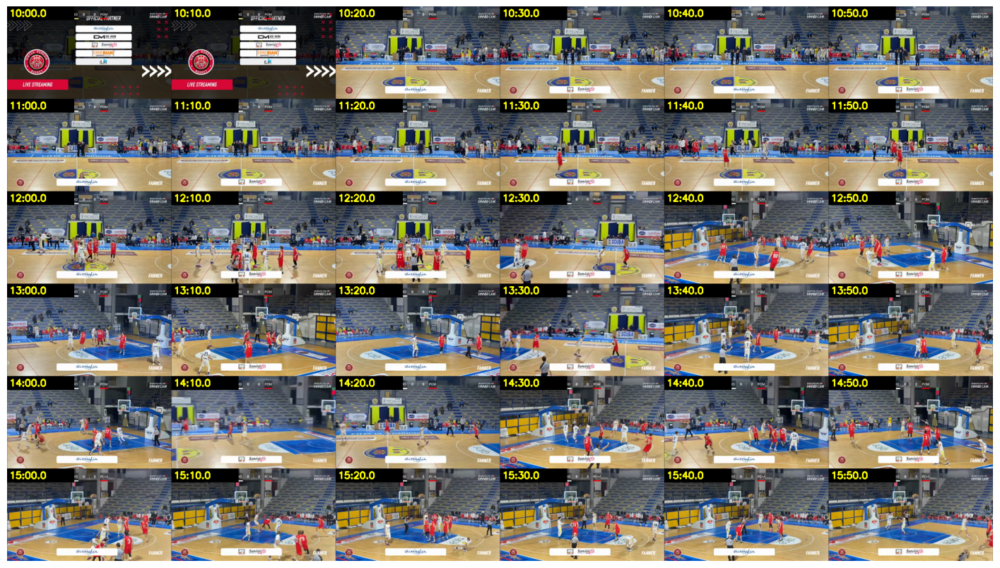

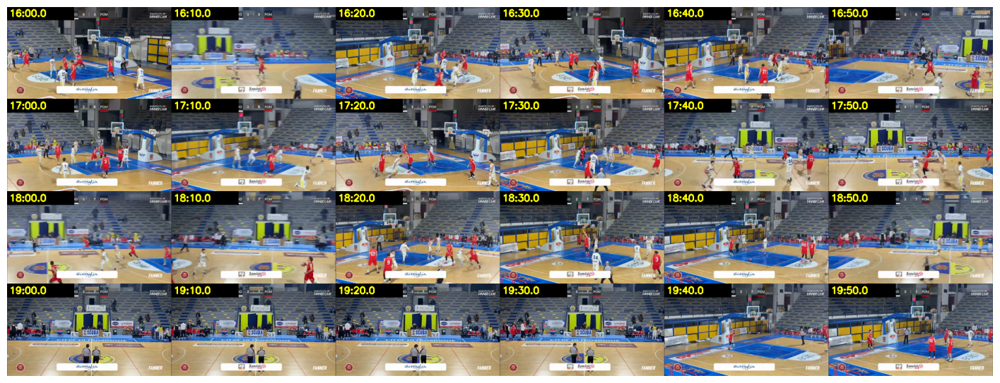

Bordo rosso = tratto già tagliato. Cerca minuti di gioco continuo (niente time-out, pause, tiri liberi lunghi).


In [ ]:
def grab(t, w=320, h=180):
    # un fotogramma al secondo t, letto con ffmpeg (OpenCV non decodifica l'AV1 dei video YouTube)
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.2f}', '-i', str(SRC), '-frames:v', '1',
                        '-vf', f'scale={w}:{h}', '-f', 'image2pipe', '-vcodec', 'png', '-'], capture_output=True)
    if not r.stdout: return None
    return cv2.imdecode(np.frombuffer(r.stdout, np.uint8), cv2.IMREAD_COLOR)

assert grab(60) is not None, 'ffmpeg non riesce a leggere il video: mandami il messaggio di errore'

DA, A = '10:00', '20:00'           # tratto da sfogliare (mm:ss oppure h:mm:ss)
PASSO_S = 10; COLONNE = 6

thumbs = []
for t in tqdm(np.arange(to_s(DA), min(to_s(A), DUR), PASSO_S), desc='panoramica'):
    f = grab(t)
    if f is None: continue
    cv2.rectangle(f, (0, 0), (130, 26), (0, 0, 0), -1)
    cv2.putText(f, mmss(t), (4, 19), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 255, 255), 2)
    if any(a <= t < b for a, b in ESISTENTI.values()): cv2.rectangle(f, (0, 0), (319, 179), (0, 0, 255), 6)
    thumbs.append(f)
while len(thumbs) % COLONNE: thumbs.append(np.zeros_like(thumbs[0]))
rows = [np.hstack(thumbs[i:i + COLONNE]) for i in range(0, len(thumbs), COLONNE)]
for i in range(0, len(rows), 6):
    plt.figure(figsize=(18, 3 * len(rows[i:i + 6]))); plt.imshow(cv2.cvtColor(np.vstack(rows[i:i + 6]), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
print('Bordo rosso = tratto già tagliato. Cerca minuti di gioco continuo (niente time-out, pause, tiri liberi lunghi).')

### A2. Anteprima di un minuto candidato

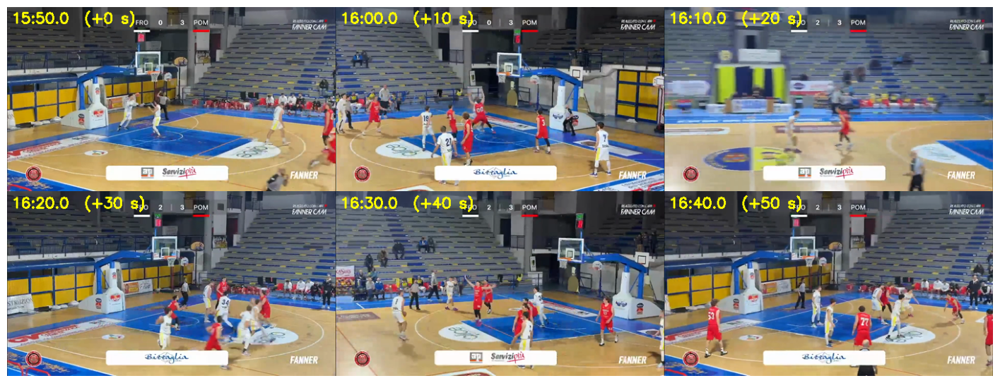

In [ ]:
INIZIO = '15:50'

t0 = to_s(INIZIO); ims = []
for t in t0 + np.arange(0, CLIP_S, 10):
    f = grab(t, 480, 270)
    if f is None: continue
    cv2.putText(f, f'{mmss(t)}  (+{t - t0:.0f} s)', (6, 24), cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 255, 255), 2); ims.append(f)
assert ims, f'Nessun fotogramma letto a partire da {INIZIO}: controlla che sia prima di {mmss(DUR)}'
while len(ims) < 6: ims.append(np.zeros_like(ims[0]))
plt.figure(figsize=(18, 7)); plt.imshow(cv2.cvtColor(np.vstack([np.hstack(ims[:3]), np.hstack(ims[3:6])]), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

### A3. Taglio delle clip scelte

In [ ]:
TAGLI = [                          # (nome, inizio) — ogni clip dura CLIP_S secondi
    ('frosinone_c2', '15:50'),
]
FPS_CLIP = 30                      # le clip vengono portate a 30 fps come i video NBA (alcuni parametri delle regole v3 sono in frame)

assert shutil.which('ffmpeg'), 'ffmpeg mancante'
for nome, inizio in TAGLI:
    a = to_s(inizio); b = a + CLIP_S; dst = OUT_DIR / f'{nome}.mp4'
    if dst.is_file(): print(f'= {nome}: esiste già'); continue
    over = [k for k, (x, y) in ESISTENTI.items() if a < y and x < b]
    if over: print(f'✗ {nome}: si sovrappone a {over}, scegli un altro inizio'); continue
    if b > DUR: print(f'✗ {nome}: va oltre la fine del video'); continue
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-ss', f'{a:.2f}', '-to', f'{b:.2f}', '-i', str(SRC),
                    '-vf', f'fps={FPS_CLIP}', '-c:v', 'libx264', '-crf', '18', '-an', str(dst)], check=True)
    ESISTENTI[nome] = (a, b); REGISTRO.write_text(json.dumps(ESISTENTI, indent=1))
    cap = cv2.VideoCapture(str(dst)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fr = cap.get(cv2.CAP_PROP_FPS); cap.release()
    print(f'✓ {nome}: {mmss(a)} - {mmss(b)} -> {dst.name} | {fr:.2f} fps, {n} frame (attesi circa {CLIP_S * FPS_CLIP})')

✓ frosinone_c2: 15:50.0 - 16:50.0 -> frosinone_c2.mp4 | 30.00 fps, 1800 frame (attesi circa 1800)


## B. Prova rapida su 6 fotogrammi: giocatori, palla, keypoint del campo, omografia

Usa gli stessi modelli della pipeline: YOLO11m Roboflow per i giocatori (640 px), il detector della palla di E4 (1280 px), il modello dei keypoint del campo con le misure **FIBA**. I punti verdi sono **tutti** i riferimenti del campo FIBA riproiettati con l'omografia: se cadono sulle linee vere, l'omografia è buona.

Output()

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


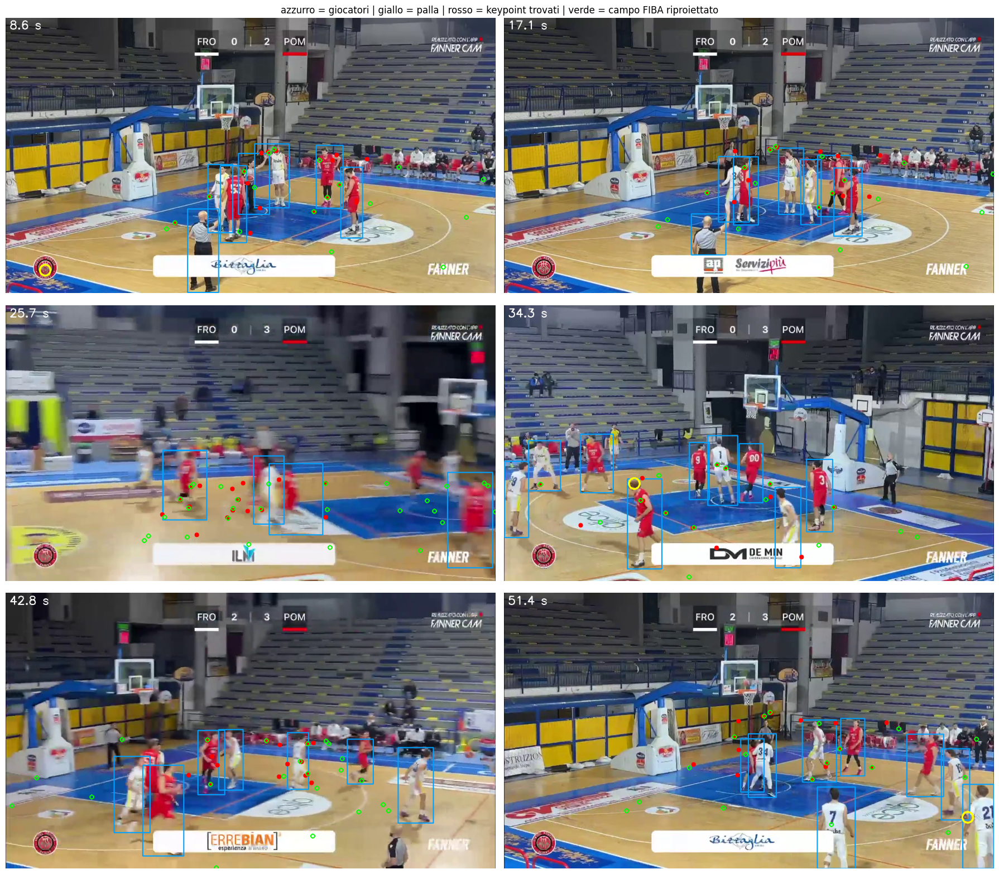

,tempo_s,giocatori,palla_conf_max,keypoint_conf>=0.5,omografia,errore_fit_px
0,8.6,7,0.54,17,True,22.0
1,17.1,7,0.00,15,True,20.5
2,25.7,5,0.00,16,True,7.3
3,34.3,9,0.43,13,True,3.2
4,42.8,7,0.00,15,True,20.0
5,51.4,8,0.37,15,True,14.2


Omografia con almeno 6 keypoint (confidenza >= 0.3) e 6 inlier RANSAC.


In [ ]:
from ultralytics import YOLO
from inference import get_model
from sports import MeasurementUnit
from sports.basketball import CourtConfiguration, League
try:
    from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    API_KEY = os.environ.get('ROBOFLOW_API_KEY') or __import__('getpass').getpass('API key Roboflow: ')

PROVA = OUT_DIR / 'frosinone_c2.mp4'        # <-- clip da provare
KP_CONF = 0.3                             # soglia dei keypoint del campo (NBA: 0,5; qui 0,3, vedi cella C)
WORK_W = 1280
det = YOLO(str(ROOT / 'models' / 'yolo11m_ft.pt')); ball = YOLO(str(ROOT / 'models' / 'ball_detector.pt'))
court_model = get_model(model_id='basketball-court-detection-2/14', api_key=API_KEY)
fiba = CourtConfiguration(league=League.FIBA, measurement_unit=MeasurementUnit.FEET)
V = np.asarray(fiba.vertices, dtype=np.float32)
PLAYERS = [i for i, n in det.names.items() if n.startswith('player')]

cap = cv2.VideoCapture(str(PROVA)); nf = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS)
righe, ims = [], []
for fi in np.linspace(0, nf - 1, 8).astype(int)[1:7]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi)); ok, f = cap.read()
    if not ok: continue
    if f.shape[1] != WORK_W: f = cv2.resize(f, (WORK_W, int(round(f.shape[0] * WORK_W / f.shape[1]))), interpolation=cv2.INTER_AREA)
    img = f.copy()
    r = det.predict(f, conf=0.3, imgsz=640, classes=PLAYERS, verbose=False)[0]
    for x1, y1, x2, y2 in r.boxes.xyxy.cpu().numpy().astype(int): cv2.rectangle(img, (x1, y1), (x2, y2), (255, 160, 0), 2)
    b = ball.predict(f, conf=0.25, imgsz=1280, verbose=False)[0]
    bconf = float(b.boxes.conf.max()) if len(b.boxes) else 0.0
    for x1, y1, x2, y2 in b.boxes.xyxy.cpu().numpy().astype(int): cv2.circle(img, ((x1 + x2) // 2, (y1 + y2) // 2), 14, (0, 255, 255), 3)
    k = court_model.infer(f, confidence=0.3)[0]; n_kp = 0; omo = False; err = np.nan
    if k.predictions:
        pr = max(k.predictions, key=lambda p: p.confidence)
        pts = [p for p in pr.keypoints if p.confidence >= KP_CONF and 0 <= p.class_id < len(V)]
        n_kp = len(pts)
        for p in pts: cv2.circle(img, (int(p.x), int(p.y)), 6, (0, 0, 255), -1)
        if n_kp >= 6:
            fwd, mask = cv2.findHomography(V[[p.class_id for p in pts]], np.float32([[p.x, p.y] for p in pts]), cv2.RANSAC, 8.0)
            if fwd is not None and mask is not None and mask.sum() >= 6:
                omo = True
                proj = cv2.perspectiveTransform(V[[p.class_id for p in pts]].reshape(-1, 1, 2), fwd).reshape(-1, 2)
                err = float(np.median(np.linalg.norm(proj - np.float32([[p.x, p.y] for p in pts]), axis=1)))
                for x, y in cv2.perspectiveTransform(V.reshape(-1, 1, 2), fwd).reshape(-1, 2):
                    if 0 <= x < img.shape[1] and 0 <= y < img.shape[0]: cv2.circle(img, (int(x), int(y)), 5, (0, 255, 0), 2)
    cv2.putText(img, f'{fi / fps:.1f} s', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
    ims.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    righe.append({'tempo_s': round(fi / fps, 1), 'giocatori': len(r.boxes), 'palla_conf_max': round(bconf, 2),
                  'keypoint_conf>=0.5': n_kp, 'omografia': omo, 'errore_fit_px': round(err, 1) if omo else None})
cap.release()
fig, ax = plt.subplots(3, 2, figsize=(18, 16))
for a, im in zip(ax.ravel(), ims): a.imshow(im); a.axis('off')
plt.suptitle('azzurro = giocatori | giallo = palla | rosso = keypoint trovati | verde = campo FIBA riproiettato'); plt.tight_layout(); plt.show()
display(pd.DataFrame(righe))
print(f'Omografia con almeno 6 keypoint (confidenza >= {KP_CONF}) e 6 inlier RANSAC.')

## C. Configurazione (notebook 15, regole v3 congelate)

Uguale al notebook 15 v3, tranne: cartelle (`videos/amatoriali/clip`, `events_amatoriali`), file delle annotazioni, `LEAGUE_NAME = 'fiba'`, posizione delle cifre e del logo del punteggio in sovrimpressione, zona della sovrimpressione, **soglia dei keypoint del campo `KP_CONF = 0.3`** (nell'NBA 0,5). Sono tutte modifiche di geometria e configurazione: le regole degli eventi restano le v3. Le coordinate del punteggio sono state verificate con la cella C2.

In [17]:
VIDEO = ROOT / 'videos' / 'amatoriali' / 'clip' / 'frosinone_c2.mp4'   # <-- la clip da analizzare
START_S, END_S = 0, None                        # tratto da analizzare (secondi); None = fino alla fine
ESCLUDI = []                                    # intervalli da ignorare (time-out, pause, inquadrature strette), in secondi della clip
LEAGUE_NAME = 'fiba'                            # campo FIBA (28 x 15 m)

WORK_W = 1280                                   # larghezza di lavoro (i video più grandi vengono ridotti)
DET_WEIGHTS = ROOT / 'models' / 'yolo11m_ft.pt'      # su clip NBA (in-domain) YOLO11m è il migliore in E1 ed è 3,5x più veloce
DET_IMGSZ = 640                                 # giocatori: 640 è il migliore in E4 (la palla ora la fa il detector dedicato a 1280)
BALL_WEIGHTS = ROOT / 'models' / 'ball_detector.pt'   # detector dedicato alla palla (notebook 16); se manca si usa la palla del detector principale
BALL_IMGSZ = 1280
DET_CONF = 0.05
COURT_MODEL_ID = 'basketball-court-detection-2/14'
HOMO_EVERY = 3
CUT_THR = 0.55                                  # somiglianza minima tra frame consecutivi; sotto = taglio di scena
SCORE_BOXES = {'L': (0.452, 0.065, 0.485, 0.108), 'R': (0.518, 0.065, 0.552, 0.108)}   # cifre del punteggio in alto (FRO a sinistra, POM a destra): verificata con C2
KP_CONF = 0.3                                   # soglia dei keypoint del campo: 0,3 invece di 0,5 (prova del 8/11: omografia nel 73% dei fotogrammi invece del 47%)
SCORE_LOGO = (0.388, 0.065, 0.432, 0.108)      # scritta 'FRO' a sinistra del punteggio: serve a capire se la sovrimpressione è visibile; verificata con C2
SCORE_SIDE = {0: 'R', 1: 'L'}                  # squadra 0 = maglia più scura (rossa, Pomezia, a destra); squadra 1 = bianca (Frosinone, a sinistra): verificato
SCORE_THR = 0.035; SCORE_HOLD_S = 1.5; SCORE_FRAC = 0.8; MADE_WINDOW_S = 6.0   # cambio del punteggio stabile per 1,5 s, entro 6 s dal tiro
OUT_MARGIN_FT = 3.0; OUT_FRAC = 0.6            # persona fuori dal campo (oltre 3 ft dalle linee) per il 60% del tempo: panchina/tifosi/staff
TRACK_REFEREES = False                          # traccia anche i box "referee": il detector chiama spesso arbitro chi ha la maglia scura; si decide poi a livello di traccia
OCC_IOU = 1.0                                   # colore della maglia letto solo quando il giocatore non è sovrapposto ad altri (se possibile)
MIN_SCENE_S = 1.0                               # tagli più vicini di così (dissolvenze) contano come uno solo
TRACK_BUFFER_S = 2.0                            # quanto il tracker "ricorda" un giocatore non visto prima di dargli un ID nuovo
FT_TO_M = 0.3048

# tracce e squadre (come notebook 13/14)
INTERP_MAX_GAP = 20; DUP_IOU = 0.7; SPLIT_MIN_SAMPLES = 5; OUTLIER_K = 3.0
SCOREBOARD_REL = (0.30, 0.86, 0.69, 0.95)       # banner pubblicitario in basso: i piedi che finiscono lì sotto sono coperti; verificata con C2

# palla (tracker di Kalman)
BALL_MIN_CONF = 0.15        # candidati palla considerati
BALL_INIT_CONF = 0.40       # confidenza per (ri)agganciare la palla
BALL_GATE = 0.05            # raggio di ricerca per frame di assenza (frazione della larghezza)
BALL_MAX_MISS = 8           # frame senza conferma dopo i quali la palla è persa
BALL_FILL = 4               # buchi riempiti tra punti accettati

# possesso ed eventi (come notebook 14 v2)
POSS_CONF = 0.30; POSS_RADIUS = 0.35; POSS_MIN = 5; POSS_LOST = 10
MIN_SEG_S = 0.4; STEAL_MIN_S = 1.5; PASS_MIN_M = 1.0; SWITCH_DIST_M = 1.0; PASS_MAX_GAP_S = 2.0
SHOT_MIN_FRAMES = 3; SHOT_WINDOW_S = 3.0; MADE_CONF = 0.75; MADE_MIN_FRAMES = 3   # su az1 "ball-in-basket" arriva a 0,69 anche sui tiri sbagliati
EVENT_TOL_S = 1.0
RIM_CONF = 0.30; RIM_MIN_FRAMES = 2; SHOT_LOOKBACK_S = 2.0   # tiro = la palla arriva vicino al ferro dopo aver lasciato un giocatore
PASS_FREE_FRAMES = 2; PASS_LONG_M = 4.0                     # passaggio/palla rubata: palla vista libera in volo, oppure distanza >= 4 m
PASS_SEEN_BEFORE_S = 0.5    # chi riceve deve essere già in campo da almeno 0,5 s (se "nasce" con la palla, era solo non rilevato)
PASS_MAX_BLIND_S = 0.5      # buco massimo senza vedere la palla tra i due possessi (se è più lungo non si può dire che sia un passaggio)
PASS_HOLD_S = 0.6           # se la palla non si vede in volo, chi riceve deve tenerla almeno 0,6 s
POSS_TIE = 0.15             # palla "in mezzo" a più giocatori: a parità di distanza si preferisce il compagno di chi l'aveva
REB_MAX_GAP_S = 3.0         # il rimbalzo può arrivare fino a 3 s dopo la fine del possesso del tiratore (palla in volo, cambi di telecamera)
STEAL_HELD_N = 5             # v3: chi recupera deve avere la palla vista DENTRO il box per almeno 5 frame (non solo vicina)
STEAL_GAP_S = 2.0           # v3: per le palle rubate il possesso di squadra continua anche dopo un taglio di scena (buco <= 2 s)
REB_HOLD_FRAC = 0.25        # rimbalzo solo se la palla, quando è visibile, sta DENTRO il box del rimbalzista almeno nel 25% dei frame (non solo vicina)
REB_MIN_S = 1.0             # rimbalzo = prima squadra che tiene la palla almeno 1 s dopo il tiro (non chi la tocca per un attimo)
VIDEO_EVENTS = 'auto'       # eventi disegnati nel video: 'auto' (quelli del modello) o 'manuale'
SHOW_PASSES = True; PASS_SHOW_S = 2.0   # passaggi nel video: frecce che spariscono dopo 2 s (False = non disegnarli)
MADE_THROUGH = False        # True = in più la palla deve essere vista sotto il ferro (su az1 non distingue: anche i tiri sbagliati ricadono lì)

MANUAL = ROOT / 'annotations' / 'eventi_manuali_amatoriali.csv'   # eventi scritti a mano (lavagna semi-automatica + riferimento)
CLIP_ID = VIDEO.stem
BALL_SOURCE = 'olympic'            # 'e4' = detector del notebook 16 | 'olympic' = modello Roboflow Olympic-SK (cella D0)
OUT = ROOT / 'events_amatoriali' / (CLIP_ID + ('_olympic' if BALL_SOURCE == 'olympic' else '')); OUT.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO)); assert cap.isOpened(), f'Video non trovato: {VIDEO}'
FPS = cap.get(cv2.CAP_PROP_FPS) or 30.0; TOT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
SRC_W, SRC_H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
F0 = int(START_S * FPS); F1 = min(TOT, int(END_S * FPS)) if END_S else TOT
N = F1 - F0
W_IMG = min(WORK_W, SRC_W); H_IMG = int(round(SRC_H * W_IMG / SRC_W))
print(f'{CLIP_ID}: {SRC_W}x{SRC_H} a {FPS:.2f} fps -> analizzo {N} frame ({N / FPS:.1f} s) a {W_IMG}x{H_IMG}')
excluded = np.zeros(N, bool)
for a, b in ESCLUDI: excluded[max(0, int((a - START_S) * FPS)):max(0, int((b - START_S) * FPS))] = True

def frames_iter(step=1, wanted=None, desc=None):
    # legge i frame dal video uno alla volta (niente video intero in memoria)
    cap = cv2.VideoCapture(str(VIDEO))
    for _ in range(F0): cap.grab()
    for fi in tqdm(range(N), desc=desc, leave=False, disable=desc is None):
        ok, f = cap.read()
        if not ok: break
        if fi % step or (wanted is not None and fi not in wanted): continue
        yield fi, (cv2.resize(f, (W_IMG, H_IMG), interpolation=cv2.INTER_AREA) if f.shape[1] != W_IMG else f)
    cap.release()

frosinone_c2: 1280x720 a 30.00 fps -> analizzo 1800 frame (60.0 s) a 1280x720


### C2. Controllo della posizione del punteggio e della sovrimpressione

Rettangoli disegnati su un fotogramma della clip: **rosso** = cifre del punteggio (sinistra e destra), **giallo** = stemma usato per capire se la sovrimpressione è visibile, **blu** = zona in cui i piedi dei giocatori sono coperti. Se un rettangolo non è al posto giusto, correggi i valori nella cella C e rieseguila. Sotto, i ritagli ingranditi: ogni rettangolo rosso deve contenere **solo** le cifre di una squadra.

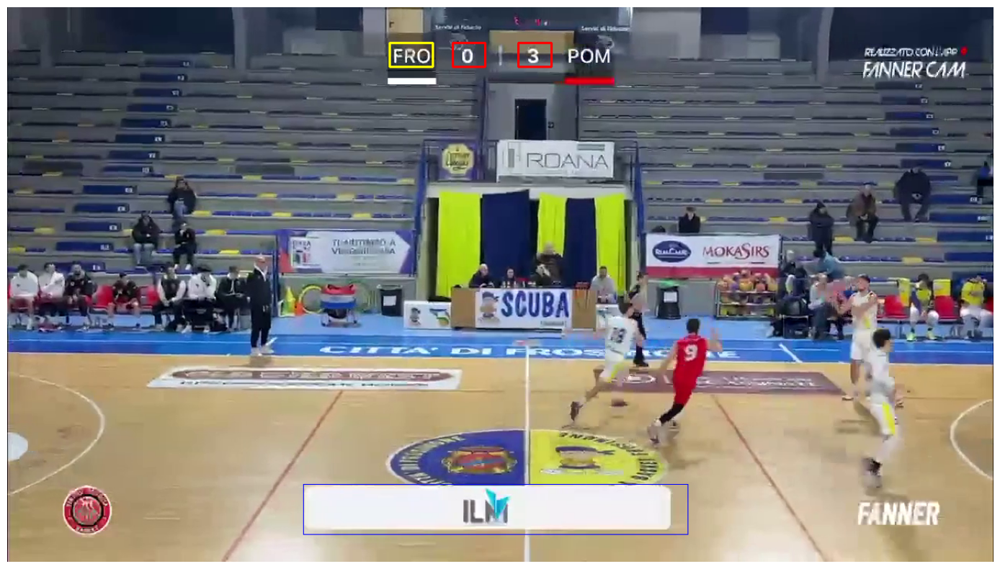

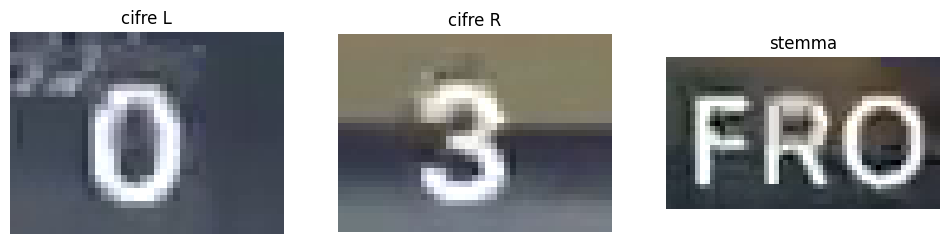

In [18]:
T_CHECK = 5.0                      # secondo della clip da usare (scegline uno con la sovrimpressione visibile)
fr = next(f for fi, f in frames_iter() if fi >= int(T_CHECK * FPS))
img = fr.copy()
def rect(box, col, w=2):
    x1, y1, x2, y2 = box; cv2.rectangle(img, (int(x1 * W_IMG), int(y1 * H_IMG)), (int(x2 * W_IMG), int(y2 * H_IMG)), col, w)
for b in SCORE_BOXES.values(): rect(b, (0, 0, 255))
rect(SCORE_LOGO, (0, 255, 255))
if SCOREBOARD_REL: rect(SCOREBOARD_REL, (255, 0, 0), 1)
plt.figure(figsize=(18, 10)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
crops = [('cifre L', SCORE_BOXES['L']), ('cifre R', SCORE_BOXES['R']), ('stemma', SCORE_LOGO)]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (t, (x1, y1, x2, y2)) in zip(ax, crops):
    a.imshow(cv2.cvtColor(fr[int(y1 * H_IMG):int(y2 * H_IMG), int(x1 * W_IMG):int(x2 * W_IMG)], cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis('off')
plt.show()

## D. Pipeline (celle del notebook 15 v3, invariate)

Prima di eseguire da qui in poi: **annota gli eventi della clip** in `annotations/eventi_manuali_amatoriali.csv` (stesse colonne del file NBA: `clip, tipo, tempo_s, da, a, note`; `clip` = nome della clip, per esempio `frosinone_c2`). I risultati vanno in `events_amatoriali/<clip>/` (con la palla Olympic-SK in `events_amatoriali/<clip>_olympic/`). Ogni clip ha un nome nuovo: detection e omografie sono in cache nella cartella della clip.

In [19]:
# D0. Palla con il modello Olympic-SK (Roboflow): calcolata una volta su tutta la clip e salvata (riprende da dove si era fermata)
OLY_ID = 'olympic-sk-basketball-dataset-v2/14'
MODO = 'server'                     # 'server' = Roboflow serverless (circa 0,5-1 s per fotogramma) | 'locale' = CPU di Colab (circa 8 s)
CLASSI_PALLA = {'ball', 'basketball'}
ZONE_GRAFICA = [(0.00, 0.80, 0.16, 1.00), (0.30, 0.86, 0.69, 0.95), (0.80, 0.85, 1.00, 1.00), (0.38, 0.05, 0.60, 0.12)]
try: API_KEY
except NameError:
    from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
if MODO == 'server':
    from inference_sdk import InferenceHTTPClient, InferenceConfiguration
    _cli = InferenceHTTPClient(api_url='https://serverless.roboflow.com', api_key=API_KEY).configure(
        InferenceConfiguration(confidence_threshold=0.05, max_detections=20))
    def _pred(f): return [(q['x'], q['y'], q['width'], q['height'], q['confidence'], q['class']) for q in _cli.infer(f, model_id=OLY_ID).get('predictions', [])]
else:
    from inference import get_model
    _m = get_model(model_id=OLY_ID, api_key=API_KEY)
    def _pred(f): return [(q.x, q.y, q.width, q.height, q.confidence, q.class_name) for q in _m.infer(f, confidence=0.05)[0].predictions]
def _in_grafica(x, y): return any(a * W_IMG <= x <= c * W_IMG and b * H_IMG <= y <= d * H_IMG for a, b, c, d in ZONE_GRAFICA)

pre_file = OUT / f'palla_olympic_n{N}_w{W_IMG}.npy'; part_file = OUT / 'palla_olympic_parziale.json'
if pre_file.is_file():
    print('[cache] palla Olympic-SK già calcolata:', pre_file.name)
else:
    st = json.loads(part_file.read_text()) if part_file.is_file() else {'fatto_fino_a': -1, 'righe': []}
    for fi, f in frames_iter(desc='palla Olympic-SK'):
        if fi <= st['fatto_fino_a']: continue
        for tent in range(3):
            try: P = _pred(f); break
            except Exception as e:
                if tent == 2: raise
                time.sleep(3)
        for x, y, w, h, c, name in P:
            if name.lower() in CLASSI_PALLA and not _in_grafica(x, y):
                st['righe'].append([fi, x - w / 2, y - h / 2, x + w / 2, y + h / 2, float(c), -1])
        st['fatto_fino_a'] = fi
        if fi % 50 == 0: part_file.write_text(json.dumps(st))
    B = np.array(st['righe'], dtype=float).reshape(-1, 7); np.save(pre_file, B); part_file.unlink(missing_ok=True)
B = np.load(pre_file)
print(f'candidati palla: {len(B)} | fotogrammi con almeno un candidato: {len(np.unique(B[:, 0])) if len(B) else 0} su {N} '
      f'| con confidenza >= 0,4: {len(np.unique(B[B[:, 5] >= 0.4, 0])) if len(B) else 0}')

[cache] palla Olympic-SK già calcolata: palla_olympic_n1800_w1280.npy
candidati palla: 6400 | fotogrammi con almeno un candidato: 1709 su 1800 | con confidenza >= 0,4: 249


## 2. Detection ad alta risoluzione, tagli di scena e tracking (BoT-SORT, riavviato a ogni taglio)

In [20]:
from ultralytics import YOLO, RTDETR
import trackers as T
model = RTDETR(str(DET_WEIGHTS)) if 'rtdetr' in str(DET_WEIGHTS).lower() else YOLO(str(DET_WEIGHTS))
NAMES = model.names

def iou_xyxy(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    ar = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

BALL_SOURCE = globals().get('BALL_SOURCE', 'e4')          # 'e4' = detector del notebook 16, 'olympic' = modello Roboflow (cella D0)
USE_BALL = BALL_WEIGHTS.is_file() or BALL_SOURCE == 'olympic'
ball_model = YOLO(str(BALL_WEIGHTS)) if (USE_BALL and BALL_SOURCE == 'e4') else None
BALL_ID = [i for i, n in NAMES.items() if n == 'ball'][0]
if BALL_SOURCE == 'olympic':
    _bp_file = OUT / f'palla_olympic_n{N}_w{W_IMG}.npy'
    assert _bp_file.is_file(), f'Manca {_bp_file.name}: esegui prima la cella D0'
    _B = np.load(_bp_file); _B[:, 6] = BALL_ID
    _B = _B[np.argsort(_B[:, 0], kind='stable')] if len(_B) else _B
    _u, _ix = np.unique(_B[:, 0].astype(int), return_index=True) if len(_B) else ([], [])
    BALL_PRE = {int(k): a for k, a in zip(_u, np.split(_B, _ix[1:]))} if len(_B) else {}
print('palla:', {'olympic': 'modello Olympic-SK (Roboflow, cella D0)', 'e4': 'detector dedicato (notebook 16)'}[BALL_SOURCE] if USE_BALL else 'detector principale')
tag = f's{F0}_n{N}_w{W_IMG}_i{DET_IMGSZ}' + ('_ball' if USE_BALL else '') + ('_olympic' if BALL_SOURCE == 'olympic' else '')
dcache, ccache = OUT / f'detections_{tag}.npy', OUT / f'cuts_{tag}.json'
have_det = dcache.is_file() and ccache.is_file()
D = np.load(dcache) if have_det else None
det_by = {}
if have_det and len(D):
    D = D[np.argsort(D[:, 0], kind='stable')]; u, idx = np.unique(D[:, 0].astype(int), return_index=True)
    det_by = {int(k): a for k, a in zip(u, np.split(D, idx[1:]))}
PLAYER_IDS = [i for i, n in NAMES.items() if n.startswith('player') or (TRACK_REFEREES and n == 'referee')]
REF_ID = next((i for i, n in NAMES.items() if n == 'referee'), -1)
def nms_any(p, thr=0.5):
    # box "referee" tenuti solo se sulla stessa persona non c'è già un box "player" (il tracking dei giocatori resta come prima)
    if len(p) < 2: return p
    isr = p[:, 6].astype(int) == REF_ID
    if not isr.any() or isr.all(): return p
    M = iou_xyxy(p[isr, 1:5], p[~isr, 1:5])
    keep_r = M.max(1) <= thr
    return np.concatenate([p[~isr], p[isr][keep_r]])
rows_det, cuts, prev_h = [], [] if not have_det else json.loads(ccache.read_text()), None
rows_trk, tracker, scene = [], None, -1
def merge_cuts(c):
    out = []
    for x in sorted(c):
        if not out or x - out[-1] >= MIN_SCENE_S * FPS: out.append(x)
    return out
cuts = merge_cuts(cuts); cut_set = set(cuts)
import inspect
_bp = [k for k in inspect.signature(T.BoTSORTTracker).parameters if 'buffer' in k or 'lost' in k]
def new_tracker():
    kw = {_bp[0]: int(TRACK_BUFFER_S * FPS)} if _bp else {}
    return T.BoTSORTTracker(frame_rate=FPS, **kw)
print('memoria del tracker:', f'{_bp[0]} = {int(TRACK_BUFFER_S * FPS)} frame' if _bp else 'parametro non trovato (default)')
for fi, f in frames_iter(desc='detection + tracking'):
    if not have_det:
        small = cv2.cvtColor(cv2.resize(f, (160, 90)), cv2.COLOR_BGR2HSV)
        h = cv2.calcHist([small], [0, 1], None, [30, 16], [0, 180, 0, 256]); cv2.normalize(h, h)
        if prev_h is not None and cv2.compareHist(prev_h, h, cv2.HISTCMP_CORREL) < CUT_THR and (not cuts or fi - cuts[-1] >= MIN_SCENE_S * FPS): cuts.append(fi); cut_set.add(fi)
        prev_h = h
        r = model.predict(f, imgsz=DET_IMGSZ, conf=DET_CONF, iou=0.7, verbose=False)[0]
        d = np.column_stack([np.full(len(r.boxes), fi), r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()])
        if USE_BALL and BALL_SOURCE == 'olympic':             # la palla viene dal modello Olympic-SK, calcolato nella cella D0
            db = BALL_PRE.get(fi, np.zeros((0, 7)))
            d = np.concatenate([d[d[:, 6].astype(int) != BALL_ID], db])
        elif USE_BALL:                                        # la palla viene dal detector dedicato
            rb = ball_model.predict(f, imgsz=BALL_IMGSZ, conf=0.05, verbose=False, max_det=10)[0]
            db = np.column_stack([np.full(len(rb.boxes), fi), rb.boxes.xyxy.cpu().numpy(), rb.boxes.conf.cpu().numpy(), np.full(len(rb.boxes), BALL_ID)])
            d = np.concatenate([d[d[:, 6].astype(int) != BALL_ID], db])
        rows_det.append(d); det_by[fi] = d
    if tracker is None or fi in cut_set:
        tracker = new_tracker(); scene += 1
    d = det_by.get(fi, np.zeros((0, 7)))
    p = d[np.isin(d[:, 6].astype(int), PLAYER_IDS)] if len(d) else d
    p = nms_any(p)
    tr = tracker.update(sv.Detections(xyxy=p[:, 1:5].astype(np.float32), confidence=p[:, 5].astype(np.float32),
                                      class_id=np.zeros(len(p), int)), frame=f)
    if len(tr) == 0: continue
    M = iou_xyxy(tr.xyxy, p[:, 1:5]) if len(p) else np.zeros((len(tr), 0))
    for k, (b, tid) in enumerate(zip(tr.xyxy, tr.tracker_id)):
        if tid is None or tid < 0: continue
        j = int(M[k].argmax()) if M.shape[1] else -1
        ok = j >= 0 and M[k, j] > 0.5
        rows_trk.append([fi, scene * 1000 + int(tid) + 1, *b, NAMES[int(p[j, 6])] if ok else 'player', float(p[j, 5]) if ok else np.nan])
if not have_det:
    D = np.concatenate(rows_det) if rows_det else np.zeros((0, 7)); np.save(dcache, D); ccache.write_text(json.dumps(cuts))
det = pd.DataFrame(D, columns=['frame', 'x1', 'y1', 'x2', 'y2', 'conf', 'cls'])
det['frame'] = det.frame.astype(int); det['name'] = det.cls.astype(int).map(NAMES).astype(str)
scene_of = np.zeros(N, int)
for c in cuts: scene_of[c:] += 1
tracks = pd.DataFrame(rows_trk, columns=['frame', 'track_id', 'x1', 'y1', 'x2', 'y2', 'cls', 'cls_conf'])
tracks = tracks[~excluded[tracks.frame.values]].reset_index(drop=True)

def interpolate(t, max_gap, cols=('x1', 'y1', 'x2', 'y2')):
    out = []
    for tid, g in t.groupby('track_id'):
        g = g.set_index('frame').reindex(range(int(g.frame.min()), int(g.frame.max()) + 1))
        miss = g.x1.isna(); run = (miss != miss.shift()).cumsum()
        g[list(cols)] = g[list(cols)].interpolate(limit_area='inside')
        keep = ~miss | (miss.groupby(run).transform('sum') <= max_gap)
        g = g[keep].copy(); g['track_id'] = tid; g['cls'] = g['cls'].fillna('interp')
        g.index.name = 'frame'; out.append(g.reset_index())
    return pd.concat(out, ignore_index=True)
tracks = interpolate(tracks, INTERP_MAX_GAP)
tracks['frame'] = tracks.frame.astype(int); tracks['track_id'] = tracks.track_id.astype(int)
print(f'tagli di scena: {len(cuts)} ({[round(c / FPS + START_S, 1) for c in cuts][:15]} s) | tracce: {tracks.track_id.nunique()}')
print(det[det.conf >= 0.3]['name'].value_counts().to_dict())

palla: modello Olympic-SK (Roboflow, cella D0)
memoria del tracker: lost_track_buffer = 60 frame


detection + tracking:   0%|          | 0/1800 [00:00<?, ?it/s]

tagli di scena: 0 ([] s) | tracce: 93
{'player': 12865, 'number': 4728, 'referee': 2451, 'player-in-possession': 734, 'ball': 408, 'rim': 313, 'player-jump-shot': 38, 'player-shot-block': 38, 'player-layup-dunk': 10}


## 3. Pulizia tracce, squadre e arbitro (come notebook 13/14)

colori maglia:   0%|          | 0/1800 [00:00<?, ?it/s]

campioni colore: 4275 | scartati perché sovrapposti: 0
tracce divise: 24 | tracce per squadra: {1: 56, 0: 46, -1: 14} | escluse: 14


foglio squadre:   0%|          | 0/1800 [00:00<?, ?it/s]

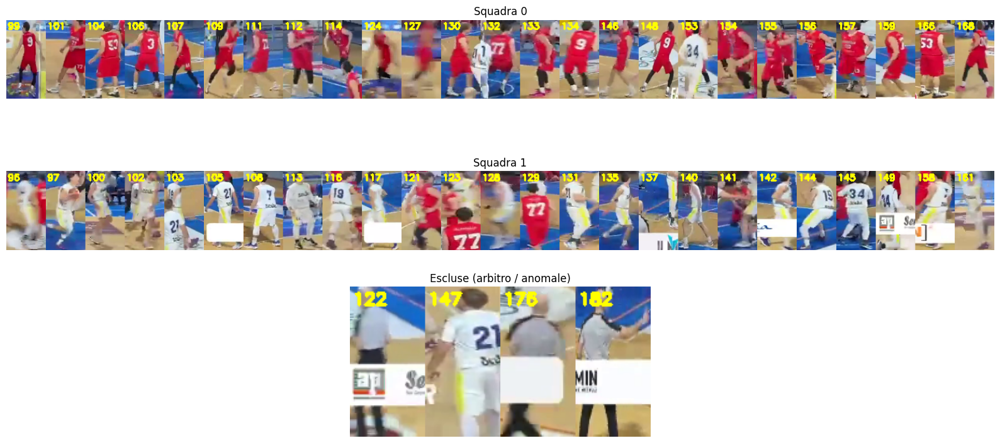

In [21]:
length = tracks.groupby('track_id').size(); drop = []
for fi, g in tracks.groupby('frame'):
    if len(g) < 2: continue
    M = iou_xyxy(g[['x1', 'y1', 'x2', 'y2']].values, g[['x1', 'y1', 'x2', 'y2']].values); np.fill_diagonal(M, 0)
    ids, idx = g.track_id.values, g.index.values
    for i, j in zip(*np.where(np.triu(M) > DUP_IOU)):
        drop.append(idx[i] if length[ids[i]] < length[ids[j]] else idx[j])
tracks = tracks.drop(index=sorted(set(drop))).reset_index(drop=True)
tracks['foot_x'] = (tracks.x1 + tracks.x2) / 2; tracks['foot_y'] = tracks.y2
tracks['foot_ok'] = tracks.y2 < H_IMG - 3
if SCOREBOARD_REL:
    sx1, sy1, sx2, sy2 = SCOREBOARD_REL[0] * W_IMG, SCOREBOARD_REL[1] * H_IMG, SCOREBOARD_REL[2] * W_IMG, SCOREBOARD_REL[3] * H_IMG
    tracks.loc[tracks.foot_x.between(sx1, sx2) & tracks.y2.between(sy1 - 6, sy2), 'foot_ok'] = False

# feature della maglia: un solo passaggio sul video, solo sui frame necessari
need = set(range(0, N, 3)); court_px = []
feat_rows = []
by_f = dict(tuple(tracks[tracks.frame % 3 == 0].groupby('frame')))
for fi, f in frames_iter(step=3, desc='colori maglia'):
    if fi % 30 == 0:
        court_px.append(cv2.cvtColor(np.ascontiguousarray(f[int(.6*H_IMG):int(.78*H_IMG), int(.2*W_IMG):int(.8*W_IMG)]), cv2.COLOR_BGR2LAB).reshape(-1, 3))
    g = by_f.get(fi)
    if g is None: continue
    bxs = g[['x1', 'y1', 'x2', 'y2']].values; Mo = iou_xyxy(bxs, bxs); np.fill_diagonal(Mo, 0)
    ov = Mo.max(1) if len(bxs) > 1 else np.zeros(len(bxs))
    for r, o in zip(g.itertuples(), ov):
        x1, y1, x2, y2 = max(0, int(r.x1)), max(0, int(r.y1)), min(W_IMG, int(r.x2)), min(H_IMG, int(r.y2))
        w, h = x2 - x1, y2 - y1
        if h < 30 or w < 8: continue
        crop = np.ascontiguousarray(f[y1 + int(.15*h):y1 + int(.5*h), x1 + int(.2*w):x2 - int(.2*w)])
        if crop.size: feat_rows.append((r.track_id, fi, cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32), o > OCC_IOU))
COURT_LAB = np.median(np.concatenate(court_px).astype(np.float32), axis=0)
def hist_of(lab):
    lab = lab[np.linalg.norm(lab - COURT_LAB, axis=1) > 25]
    if len(lab) < 20: return None
    h = np.histogramdd(lab, bins=(4, 6, 6), range=((0, 256), (0, 256), (0, 256)))[0].ravel(); return h / h.sum()
F, K, R, O = [], [], [], []
for tid, fi, lab, occ in feat_rows:
    h = hist_of(lab)
    if h is not None: F.append(h); K.append(tid); R.append(fi); O.append(occ)
F, K, R, O = np.array(F), np.array(K), np.array(R), np.array(O, bool)
if len(K):                                                     # i campioni "sovrapposti" restano solo per le tracce che non ne hanno di puliti
    has_clean = pd.Series(~O).groupby(K).transform('any').values
    keep = ~O | ~has_clean; F, K, R = F[keep], K[keep], R[keep]
    print(f'campioni colore: {len(O)} | scartati perché sovrapposti: {int((~keep).sum())}')

class KMeans2:
    def __init__(self, n_init=20, iters=100, seed=0): self.n_init, self.iters, self.rng = n_init, iters, np.random.default_rng(seed)
    def fit(self, X):
        X = np.asarray(X, np.float64); best = None
        for _ in range(self.n_init):
            C = X[self.rng.choice(len(X), 2, replace=len(X) < 2)].copy()
            for _ in range(self.iters):
                lab = self._assign(X, C)
                newC = np.array([X[lab == k].mean(0) if (lab == k).any() else C[k] for k in range(2)])
                if np.allclose(newC, C): break
                C = newC
            inertia = ((X - C[self._assign(X, C)]) ** 2).sum()
            if best is None or inertia < best[0]: best = (inertia, C)
        self.cluster_centers_ = best[1]; return self
    @staticmethod
    def _assign(X, C): return np.argmin(((X[:, None, :] - C[None]) ** 2).sum(-1), axis=1)
    def predict(self, X): return self._assign(np.asarray(X, np.float64), self.cluster_centers_)

def fit_teams(F, K):
    med = {int(t): np.median(F[K == t], axis=0) for t in np.unique(K)}
    n = pd.Series(K).value_counts()
    fit_ids = [t for t in med if n[t] >= 5] or list(med)
    outliers = set()
    for _ in range(2):
        km = KMeans2().fit(np.array([med[t] for t in fit_ids if t not in outliers]))
        lum = [(c.reshape(4, 6, 6).sum((1, 2)) * np.array([32, 96, 160, 224])).sum() for c in km.cluster_centers_]
        if lum[0] > lum[1]: km.cluster_centers_ = km.cluster_centers_[::-1].copy()
        team = {t: int(km.predict(med[t][None])[0]) for t in med}
        d = pd.Series({t: np.linalg.norm(med[t] - km.cluster_centers_[team[t]]) for t in med})
        dl = d[[t for t in fit_ids if t not in outliers]]
        thr = dl.median() + OUTLIER_K * max((dl - dl.median()).abs().median() * 1.4826, 0.25 * dl.median(), 1e-6)
        outliers |= set(d.index[d > thr])
    for t in outliers: team[t] = -1
    return km, team

km, team_of = fit_teams(F, K)
n_split = 0; lab_s = km.predict(F); next_id = int(tracks.track_id.max()) + 1; remap = []
for tid in np.unique(K):
    if team_of[int(tid)] < 0: continue
    sel = np.argsort(R[K == tid]); f_t = R[K == tid][sel]; l_t = lab_s[K == tid][sel]
    other = l_t != team_of[int(tid)]; run_start, cnt, cuts_t = None, 0, []
    for k, o in enumerate(other):
        if o: run_start = k if cnt == 0 else run_start; cnt += 1
        else:
            if cnt >= SPLIT_MIN_SAMPLES: cuts_t.append((f_t[run_start], f_t[k]))
            cnt = 0
    if cnt >= SPLIT_MIN_SAMPLES: cuts_t.append((f_t[run_start], N))
    for a, b in cuts_t:
        m = (tracks.track_id == tid) & (tracks.frame >= a) & (tracks.frame < b)
        tracks.loc[m, 'track_id'] = next_id; remap.append((tid, a, b, next_id)); next_id += 1; n_split += 1
for tid, a, b, nid in remap:
    m = (K == tid) & (R >= a) & (R < b); K[m] = nid
if n_split: km, team_of = fit_teams(F, K)
ref_by = {f: g[['x1', 'y1', 'x2', 'y2']].values for f, g in det[(det['name'] == 'referee') & (det.conf >= 0.3)].groupby('frame')}
for tid, g in tracks[tracks.frame % 3 == 0].groupby('track_id'):
    hits = [f in ref_by and iou_xyxy(np.array([[x1, y1, x2, y2]]), ref_by[f]).max() > 0.5
            for f, x1, y1, x2, y2 in g[['frame', 'x1', 'y1', 'x2', 'y2']].itertuples(index=False)]
    if hits and np.mean(hits) >= 0.3: team_of[int(tid)] = -1
tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)
print('tracce divise:', n_split, '| tracce per squadra:', pd.Series(team_of).value_counts().to_dict(),
      '| escluse:', len([t for t, k in team_of.items() if k < 0]))
TEAM_COLORS = {0: (255, 140, 30), 1: (40, 40, 230), -1: (160, 160, 160)}    # BGR: squadra 0 (scura) blu, 1 (chiara) rossa

# foglio di controllo: un ritaglio per traccia lunga
long_ids = tracks.groupby('track_id').size().loc[lambda s: s >= FPS].index
mid = {tid: int(g.frame.iloc[len(g) // 2]) for tid, g in tracks[tracks.track_id.isin(long_ids)].groupby('track_id')}
crops = {}
want = {f: [t for t, ff in mid.items() if ff == f] for f in set(mid.values())}
for fi, f in frames_iter(wanted=set(want), desc='foglio squadre'):
    for tid in want[fi]:
        r = tracks[(tracks.track_id == tid) & (tracks.frame == fi)].iloc[0]
        c = np.ascontiguousarray(f[max(0, int(r.y1)):min(H_IMG, int(r.y2)), max(0, int(r.x1)):min(W_IMG, int(r.x2))])
        if c.size and c.shape[0] > 1 and c.shape[1] > 1:
            c = cv2.resize(c, (60, 120)); cv2.putText(c, str(tid), (2, 14), cv2.FONT_HERSHEY_SIMPLEX, .45, (0, 255, 255), 2); crops[tid] = c
fig, axes = plt.subplots(3, 1, figsize=(16, 7.5))
for ax, team in zip(axes, [0, 1, -1]):
    cc = [crops[t] for t in sorted(crops) if team_of.get(t, -1) == team][:25]
    if cc: ax.imshow(cv2.cvtColor(np.hstack(cc), cv2.COLOR_BGR2RGB))
    ax.set_title(f'Squadra {team}' if team >= 0 else 'Escluse (arbitro / anomale)'); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT / 'controllo_squadre.png', dpi=130); plt.show()

tracce che il detector chiama "referee" (colore = distanza / mediana della squadra):
 track_id  campioni_colore  colore decisione
      122               12    1.54   arbitro
      126                3    2.68   arbitro
      138               10    1.86   arbitro
      176               13    1.28   arbitro
      179               10    2.47   arbitro
      182               10    1.13 giocatore
      183                4    3.01   arbitro
tracce per squadra: {1: 63, 0: 46, -1: 8} | motivi esclusione: {'REF': 6, 'NOCOL': 1, 'ANOM': 1}


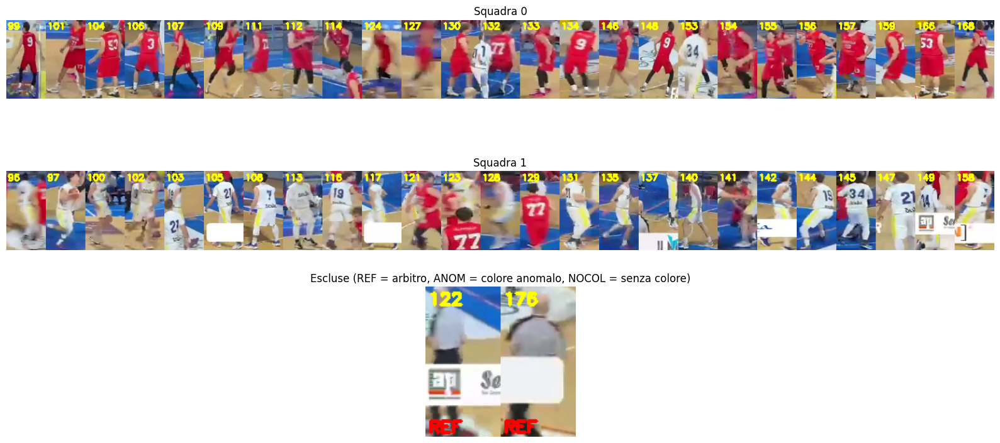

In [22]:
# 3b. ARBITRO E ANOMALE, VERSIONE CORRETTA
# arbitro = nei frame della traccia il detector è più sicuro di "referee" che di "player" (non basta che esista un box referee)
# anomala = solo tracce con abbastanza campioni di colore e molto lontane da entrambe le squadre; le tracce corte vanno alla squadra più vicina
REF_VOTE = 0.5          # quota minima di frame in cui "referee" batte "player"
OUTLIER_K2 = 5.0        # più alto = meno tracce scartate per colore
MIN_COL = 5             # campioni di colore minimi per poter scartare una traccia per colore
REF_KEEP = 1.25         # "arbitro" per il detector ma colore vicino a una squadra (distanza < 1,25 x la mediana della squadra) -> resta giocatore
                        # su az1: giocatori 1,16-1,21, arbitri 1,43-2,10, persona fuori campo 1,29
DROP_NOCOL = True       # tracce senza colore utile (frammenti corti/piccoli): eliminate invece di restare grigie

ref_all = {f: g[['x1', 'y1', 'x2', 'y2', 'conf']].values for f, g in det[det['name'] == 'referee'].groupby('frame')}
ply_all = {f: g[['x1', 'y1', 'x2', 'y2', 'conf']].values for f, g in det[det['name'].str.startswith('player')].groupby('frame')}
is_ref = {}
for tid, g in tracks[tracks.frame % 3 == 0].groupby('track_id'):
    votes = []
    for f, x1, y1, x2, y2 in g[['frame', 'x1', 'y1', 'x2', 'y2']].itertuples(index=False):
        rc = pc = 0.0
        for src, is_r in ((ref_all, True), (ply_all, False)):
            r = src.get(f)
            if r is None: continue
            iou = iou_xyxy(np.array([[x1, y1, x2, y2]]), r[:, :4])[0]
            c = float(r[iou > 0.5, 4].max()) if (iou > 0.5).any() else 0.0
            if is_r: rc = c
            else: pc = c
        votes.append(rc > pc)                                     # in questo frame il detector è più sicuro di "referee" che di "player"

    is_ref[int(tid)] = len(votes) >= 3 and np.mean(votes) >= REF_VOTE

med = {int(t): np.median(F[K == t], axis=0) for t in np.unique(K)}
n_col = pd.Series(K).value_counts()
near = {t: int(km.predict(m[None])[0]) for t, m in med.items()}
d = pd.Series({t: np.linalg.norm(m - km.cluster_centers_[near[t]]) for t, m in med.items()})
base = d[[t for t in med if not is_ref.get(t, False) and n_col[t] >= MIN_COL]]
thr = base.median() + OUTLIER_K2 * max((base - base.median()).abs().median() * 1.4826, 0.25 * base.median(), 1e-6)

team_med = {k: d[[t for t in med if near[t] == k and not is_ref.get(t, False) and n_col[t] >= MIN_COL]].median() for k in (0, 1)}
def typical(t): return t in med and n_col[t] >= MIN_COL and d[t] <= REF_KEEP * team_med[near[t]]
ref_tab = [(t, n_col.get(t, 0), round(d[t] / team_med[near[t]], 2) if t in med else None, 'giocatore' if typical(t) else 'arbitro')
           for t in sorted(k for k, v in is_ref.items() if v)]
print('tracce che il detector chiama "referee" (colore = distanza / mediana della squadra):'); print(pd.DataFrame(ref_tab, columns=['track_id', 'campioni_colore', 'colore', 'decisione']).to_string(index=False))
motivo = {}
for t in tracks.track_id.unique():
    t = int(t)
    if is_ref.get(t, False) and not typical(t): team_of[t] = -1; motivo[t] = 'REF'
    elif t not in med: team_of[t] = -1; motivo[t] = 'NOCOL'
    elif n_col[t] >= MIN_COL and d[t] > thr: team_of[t] = -1; motivo[t] = 'ANOM'
    else: team_of[t] = near[t]; motivo[t] = 'ok'
if DROP_NOCOL:
    tracks = tracks[~tracks.track_id.isin([t for t, m in motivo.items() if m == 'NOCOL'])].reset_index(drop=True)
tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)
print('tracce per squadra:', pd.Series(team_of).value_counts().to_dict(), '| motivi esclusione:',
      pd.Series(motivo)[pd.Series(motivo) != 'ok'].value_counts().to_dict())

fig, axes = plt.subplots(3, 1, figsize=(16, 7.5))
for ax, team in zip(axes, [0, 1, -1]):
    ids = [t for t in sorted(crops) if team_of.get(t, -1) == team][:25]
    cc = []
    for t in ids:
        c = crops[t].copy()
        if team < 0: cv2.putText(c, motivo[t], (2, 116), cv2.FONT_HERSHEY_SIMPLEX, .45, (0, 0, 255), 2)
        cc.append(c)
    if cc: ax.imshow(cv2.cvtColor(np.hstack(cc), cv2.COLOR_BGR2RGB))
    ax.set_title(f'Squadra {team}' if team >= 0 else 'Escluse (REF = arbitro, ANOM = colore anomalo, NOCOL = senza colore)'); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT / 'controllo_squadre.png', dpi=130); plt.show()

In [23]:
# 3c. RICUCITURA DELLE TRACCE: stesso giocatore, ID nuovo
# se una traccia finisce e poco dopo, nello stesso punto, ne nasce un'altra della stessa squadra, è lo stesso giocatore
STITCH_GAP_S = 1.0       # buco massimo tra la fine di una traccia e l'inizio dell'altra (secondi)
STITCH_DIST = 1.2        # distanza massima tra i due box, in altezze del giocatore (cresce un po' con il buco)
PASS_COEXIST_S = 0.5     # per un passaggio i due giocatori devono essere visti insieme almeno questo tempo

def stitch(tracks):
    ends = tracks.sort_values('frame').groupby('track_id').agg(f0=('frame', 'first'), f1=('frame', 'last'), team=('team', 'first'))
    first = tracks.sort_values('frame').groupby('track_id').first(); last = tracks.sort_values('frame').groupby('track_id').last()
    cand = []
    for a, ea in ends[ends.team >= 0].iterrows():
        la = last.loc[a]; ha = la.y2 - la.y1
        nxt = ends[(ends.team == ea.team) & (ends.f0 >= ea.f1 - 2) & (ends.f0 <= ea.f1 + STITCH_GAP_S * FPS) & (ends.index != a)]
        for b, eb in nxt.iterrows():
            if scene_of[int(eb.f0)] != scene_of[int(ea.f1)]: continue
            fb = first.loc[b]; hb = fb.y2 - fb.y1
            if not 0.67 <= hb / max(ha, 1) <= 1.5: continue
            gap = max(0, eb.f0 - ea.f1)
            d = np.hypot((la.x1 + la.x2 - fb.x1 - fb.x2) / 2, la.y2 - fb.y2) / max(ha, 1)
            if d <= STITCH_DIST * (1 + gap / FPS): cand.append((d, int(a), int(b)))
    succ, pred = {}, {}
    for d, a, b in sorted(cand):
        if a in succ or b in pred: continue
        succ[a], pred[b] = b, a
    root = {}
    for b in sorted(pred, key=lambda t: ends.f0[t]):
        r = pred[b]
        while r in pred: r = pred[r]
        root[b] = r
    tracks = tracks.copy(); tracks['track_id'] = tracks.track_id.replace(root)
    tracks = tracks.sort_values(['track_id', 'frame']).drop_duplicates(['track_id', 'frame']).reset_index(drop=True)
    return tracks, root

n_before = tracks.track_id.nunique()
tracks, root = stitch(tracks)
for b, r in root.items(): team_of[r] = team_of.get(r, team_of.get(b, -1))
print(f'tracce: {n_before} -> {tracks.track_id.nunique()} ({len(root)} cambi di ID ricuciti)')

tracce: 116 -> 76 (40 cambi di ID ricuciti)


## 4M. Omografia manuale con propagazione (facoltativa)

Il modello dei keypoint confonde le linee e i canestri dei campi laterali della palestra con quelli del campo principale. Qui l'omografia si ottiene **senza keypoint automatici**: clicchi i punti del campo su 3-4 fotogrammi chiave (cella 4M), poi il movimento della telecamera fra un fotogramma e il successivo viene stimato dallo sfondo (spalti, pareti; esclusi giocatori e grafiche) e l'omografia viene propagata a tutta la clip (cella 4M-2). La cella mostra anche la **deriva**: l'omografia propagata da un fotogramma chiave all'altro, confrontata con quella cliccata.

Se **non** esegui queste due celle, la cella 4 usa i keypoint automatici come prima. I risultati con i keypoint vengono copiati in `omografia_keypoint/` prima di essere sovrascritti.

copia dei risultati con i keypoint in /content/drive/MyDrive/Tesi_Basket/events_amatoriali/frosinone_c2_olympic/omografia_keypoint



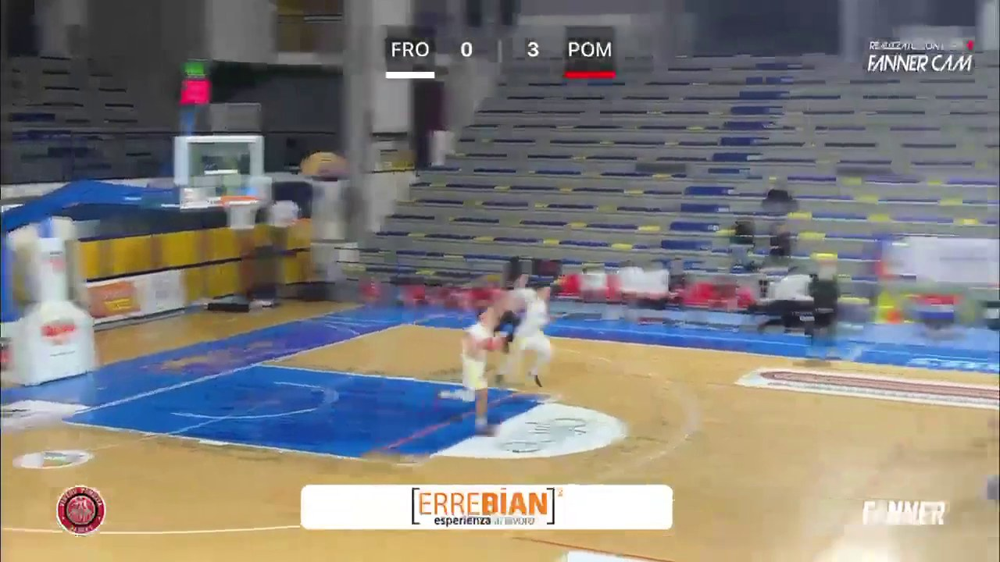
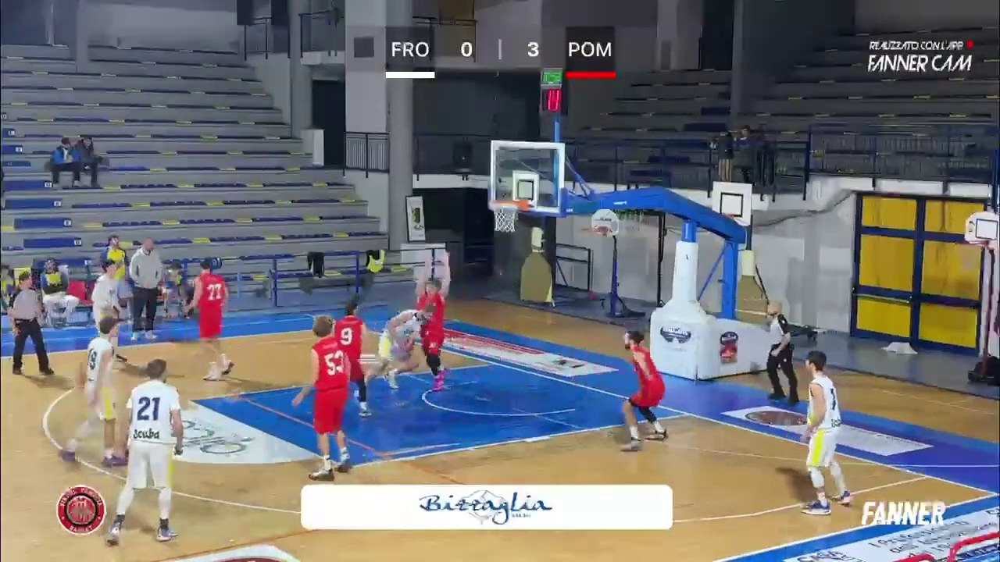
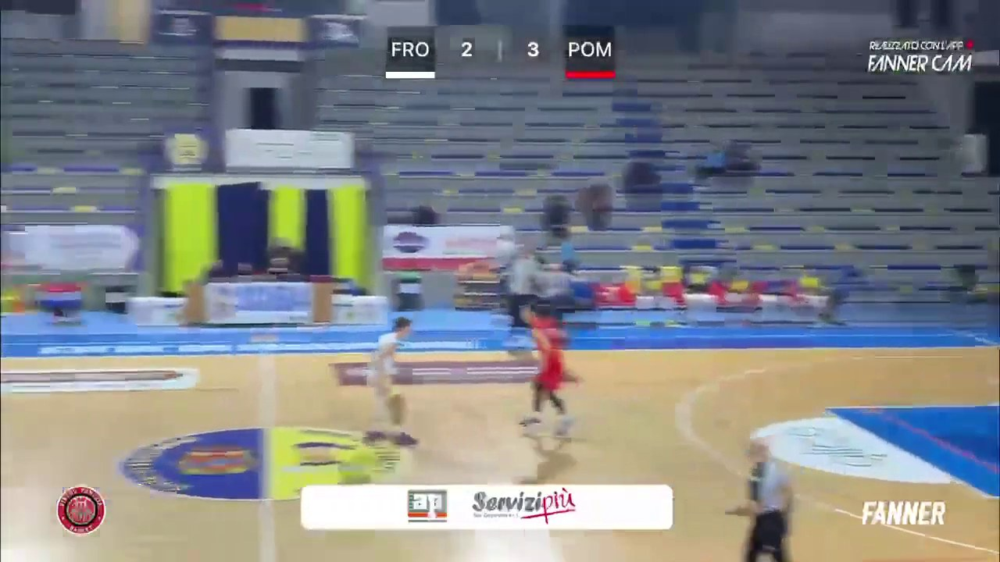
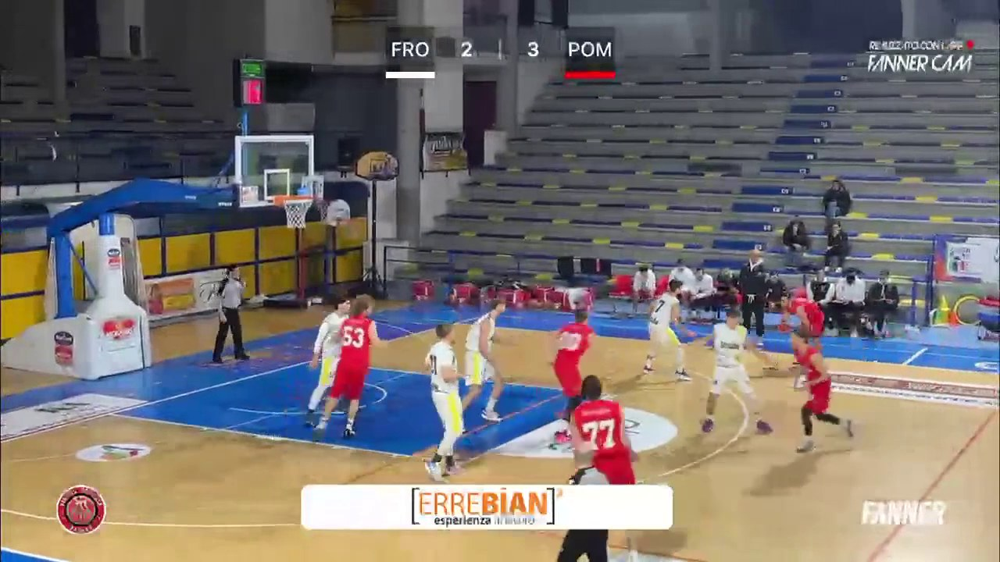
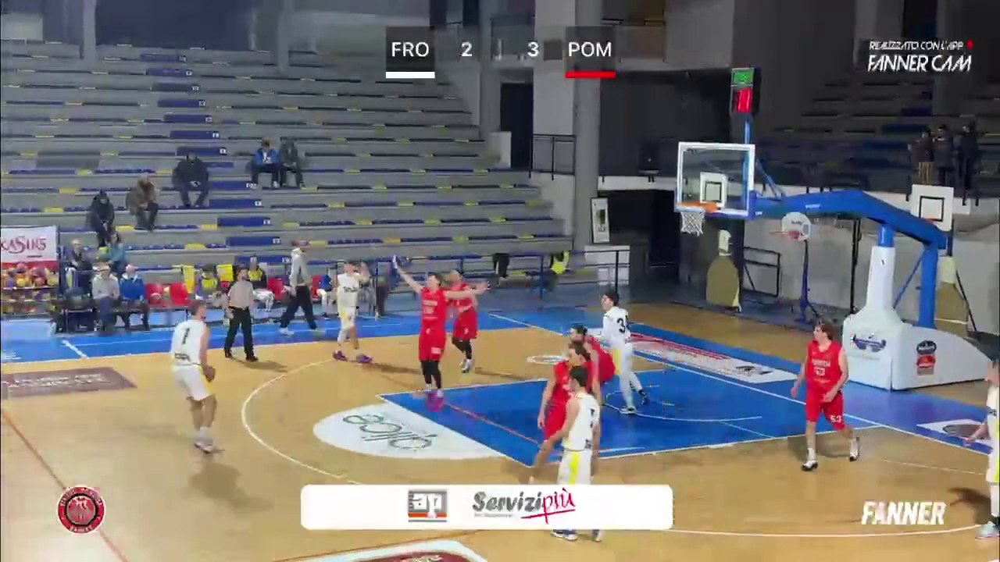
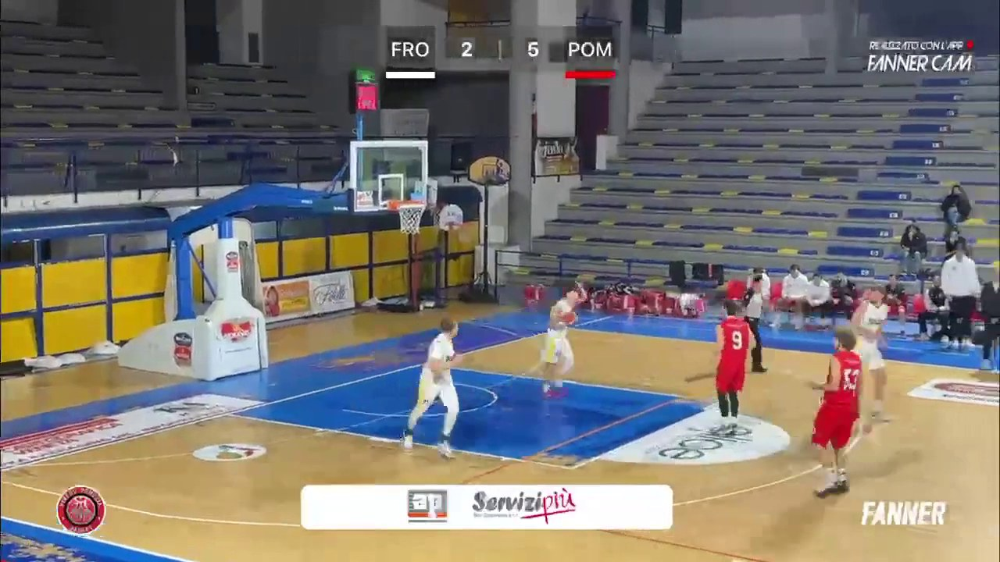

Clicca almeno 5 punti su OGNUNO dei 6 fotogrammi chiave (pulsanti ◀ ▶ in alto), poi esegui la cella 4M-2.
punti già salvati: {'2.0 s': 8, '12.0 s': 8, '20.0 s': 7, '24.0 s': 6, '40.0 s': 7, '58.0 s': 6}


In [32]:
# 4M. OMOGRAFIA MANUALE CON PROPAGAZIONE (al posto dei keypoint automatici, che si confondono con i campi laterali)
# 1) su alcuni fotogrammi chiave clicchi i punti del campo che vedi (come per la DR3);
# 2) il movimento della telecamera tra un fotogramma e il successivo si stima dallo SFONDO (spalti, pareti), escludendo giocatori e grafiche;
# 3) l'omografia di ogni fotogramma si ottiene propagando quella del fotogramma chiave più vicino (avanti e indietro).
# Approccio simile a Battelini (2020): calibrazione iniziale manuale e propagazione con il flusso ottico.
import base64
from IPython.display import HTML, display
HOMO_MODE = 'manuale'                            # la cella "4. Omografia" userà il file prodotto qui
KEY_S = [2.0, 12.0, 20.0, 24.0, 40.0, 58.0]      # <-- secondi della clip dei fotogrammi chiave (almeno 5 punti su OGNUNO)
MIN_PUNTI = 5                                    # punti cliccati necessari per un fotogramma chiave
REG_W = 640                                      # larghezza usata per stimare il movimento della camera (più piccola = più veloce)

# punti del campo FIBA in metri: x lungo il campo (0 = canestro di sinistra), y = 0 lato telecamera (vicino), 15 = lato opposto
LM = {'angolo_sx_vicino': (0, 0), 'angolo_sx_lontano': (0, 15), 'angolo_dx_vicino': (28, 0), 'angolo_dx_lontano': (28, 15),
      'metacampo_vicino': (14, 0), 'metacampo_lontano': (14, 15), 'centro': (14, 7.5),
      'cerchio_centro_vicino': (14, 5.7), 'cerchio_centro_lontano': (14, 9.3),
      'area_sx_fondo_vicino': (0, 5.05), 'area_sx_fondo_lontano': (0, 9.95), 'area_sx_lunetta_vicino': (5.8, 5.05),
      'area_sx_lunetta_lontano': (5.8, 9.95), 'lunetta_sx_punta': (7.6, 7.5),
      'area_dx_fondo_vicino': (28, 5.05), 'area_dx_fondo_lontano': (28, 9.95), 'area_dx_lunetta_vicino': (22.2, 5.05),
      'area_dx_lunetta_lontano': (22.2, 9.95), 'lunetta_dx_punta': (20.4, 7.5),
      'tre_sx_fondo_vicino': (0, 0.9), 'tre_sx_fondo_lontano': (0, 14.1), 'tre_sx_curva_vicino': (2.99, 0.9),
      'tre_sx_curva_lontano': (2.99, 14.1), 'tre_sx_punta': (8.325, 7.5),
      'tre_dx_fondo_vicino': (28, 0.9), 'tre_dx_fondo_lontano': (28, 14.1), 'tre_dx_curva_vicino': (25.01, 0.9),
      'tre_dx_curva_lontano': (25.01, 14.1), 'tre_dx_punta': (19.675, 7.5)}
def m_to_ft(x, y): return x / FT_TO_M, (15.0 - y) / FT_TO_M            # stesso sistema della mini-mappa (lato telecamera in basso)

# copia di sicurezza dei risultati con l'omografia dei keypoint (servono per il confronto finale)
BK = OUT / 'omografia_keypoint'
if not BK.exists() and (OUT / 'diagnostica.mp4').is_file():
    BK.mkdir()
    for p in list(OUT.glob('*.mp4')) + list(OUT.glob('*.png')) + list(OUT.glob('*.csv')) + [OUT / 'riepilogo.json']:
        if p.is_file(): shutil.copy2(p, BK / p.name)
    print('copia dei risultati con i keypoint in', BK)

KEY_F = [min(N - 1, int(round(s * FPS))) for s in KEY_S]
PFILE = OUT / 'punti_omografia_manuale.json'
PUNTI_M = json.loads(PFILE.read_text()) if PFILE.is_file() else {}
key_imgs = {fi: f.copy() for fi, f in frames_iter(wanted=set(KEY_F))}
def _save(): PFILE.write_text(json.dumps(PUNTI_M, indent=1))
def _add(fi, name, x, y): PUNTI_M.setdefault(str(int(fi)), {})[name] = [round(float(x), 1), round(float(y), 1)]; _save()
def _del(fi, name): PUNTI_M.get(str(int(fi)), {}).pop(name, None); _save()
if IN_COLAB:
    from google.colab import output
    output.register_callback('m4.add', _add); output.register_callback('m4.del', _del)
    imgs_js = json.dumps({str(fi): 'data:image/jpeg;base64,' + base64.b64encode(cv2.imencode('.jpg', key_imgs[fi], [cv2.IMWRITE_JPEG_QUALITY, 88])[1]).decode() for fi in KEY_F})
    opts_f = ''.join(f'<option value="{fi}">{s:.1f} s (frame {fi})</option>' for s, fi in zip(KEY_S, KEY_F))
    opts_p = ''.join(f'<option value="{k}">{k}</option>' for k in LM)
    display(HTML(f"""
<div style="font-family:sans-serif;font-size:14px">
 <div style="font-size:18px;font-weight:bold;margin-bottom:6px" id="title"></div>
 <button id="prev" style="font-size:16px">◀ fotogramma precedente</button> <button id="next" style="font-size:16px">fotogramma successivo ▶</button>
 &nbsp; <b>Fotogramma chiave:</b> <select id="kf">{opts_f}</select> &nbsp; <b>Punto:</b> <select id="nm">{opts_p}</select>
 <button id="del">Cancella il punto selezionato</button> &nbsp; <span id="st"></span>
 <div style="margin-top:6px;border:1px solid #888"><canvas id="cv" width="{W_IMG}" height="{H_IMG}" style="width:100%;cursor:crosshair"></canvas></div>
</div>
<script>
const imgs = {imgs_js}, pts = {json.dumps(PUNTI_M)};
const kf = document.getElementById('kf'), sel = document.getElementById('nm'), cv = document.getElementById('cv'), ctx = cv.getContext('2d');
let img = new Image();
function load() {{ img = new Image(); img.onload = draw; img.src = imgs[kf.value]; }}
function draw() {{
  ctx.drawImage(img, 0, 0); const P = pts[kf.value] || {{}};
  for (const [k, p] of Object.entries(P)) {{
    ctx.strokeStyle = 'red'; ctx.lineWidth = 2; ctx.beginPath(); ctx.arc(p[0], p[1], 6, 0, 2 * Math.PI); ctx.stroke();
    ctx.beginPath(); ctx.moveTo(p[0] - 10, p[1]); ctx.lineTo(p[0] + 10, p[1]); ctx.moveTo(p[0], p[1] - 10); ctx.lineTo(p[0], p[1] + 10); ctx.stroke();
    ctx.fillStyle = 'yellow'; ctx.font = 'bold 14px sans-serif'; ctx.fillText(k, p[0] + 8, p[1] - 8);
  }}
  for (const o of sel.options) o.text = o.value + (P[o.value] ? '  ✓' : '');
  for (const o of kf.options) {{ const n = Object.keys(pts[o.value] || {{}}).length; o.text = o.text.split(' [')[0] + ' [' + n + ' punti]'; }}
  document.getElementById('st').textContent = Object.keys(P).length + ' punti su questo fotogramma (ne servono almeno {MIN_PUNTI})';
}}
function go() {{ sel.selectedIndex = 0; load();
  document.getElementById('title').textContent = 'Fotogramma chiave ' + (kf.selectedIndex + 1) + ' di ' + kf.options.length + '  —  ' + kf.value / {FPS} + ' s'; }}
kf.addEventListener('change', go);
document.getElementById('prev').addEventListener('click', () => {{ if (kf.selectedIndex > 0) {{ kf.selectedIndex--; go(); }} }});
document.getElementById('next').addEventListener('click', () => {{ if (kf.selectedIndex < kf.options.length - 1) {{ kf.selectedIndex++; go(); }} }});
go();
cv.addEventListener('click', e => {{
  const r = cv.getBoundingClientRect(); const x = (e.clientX - r.left) * cv.width / r.width, y = (e.clientY - r.top) * cv.height / r.height;
  const n = sel.value; (pts[kf.value] = pts[kf.value] || {{}})[n] = [Math.round(x * 10) / 10, Math.round(y * 10) / 10];
  google.colab.kernel.invokeFunction('m4.add', [parseInt(kf.value), n, x, y], {{}}); draw();
  if (sel.selectedIndex < sel.options.length - 1) sel.selectedIndex++;
}});
document.getElementById('del').addEventListener('click', () => {{
  if (pts[kf.value]) delete pts[kf.value][sel.value];
  google.colab.kernel.invokeFunction('m4.del', [parseInt(kf.value), sel.value], {{}}); draw();
}});
</script>"""))
print(f'Clicca almeno {MIN_PUNTI} punti su OGNUNO dei {len(KEY_F)} fotogrammi chiave (pulsanti ◀ ▶ in alto), poi esegui la cella 4M-2.')
print('punti già salvati:', {f'{int(k) / FPS:.1f} s': len(v) for k, v in PUNTI_M.items()})

fotogrammi chiave usati: {60: '8 punti, residuo mediano 10.9 cm', 360: '8 punti, residuo mediano 4.3 cm', 600: '7 punti, residuo mediano 3.5 cm', 720: '6 punti, residuo mediano 8.4 cm', 1200: '7 punti, residuo mediano 4.5 cm', 1740: '6 punti, residuo mediano 4.8 cm'}


movimento della camera:   0%|          | 0/1800 [00:00<?, ?it/s]

,da_frame,a_frame,secondi,errore_mediano_cm
12,600,720,4.0,67.7
17,720,600,4.0,41.8
11,600,360,8.0,49.3
6,360,600,8.0,31.2
5,360,60,10.0,333.7
0,60,360,10.0,53.7
16,720,360,12.0,137.6
7,360,720,12.0,145.4
23,1200,720,16.0,149.7
18,720,1200,16.0,61.6


{
 "fotogrammi_chiave": 6,
 "residuo_cm_chiave": {
  "60": 10.9,
  "360": 4.3,
  "600": 3.5,
  "720": 8.4,
  "1200": 4.5,
  "1740": 4.8
 },
 "frame_con_movimento_stimato_%": 100.0,
 "inlier_mediani": 593,
 "frame_con_omografia_%": 100.0
}


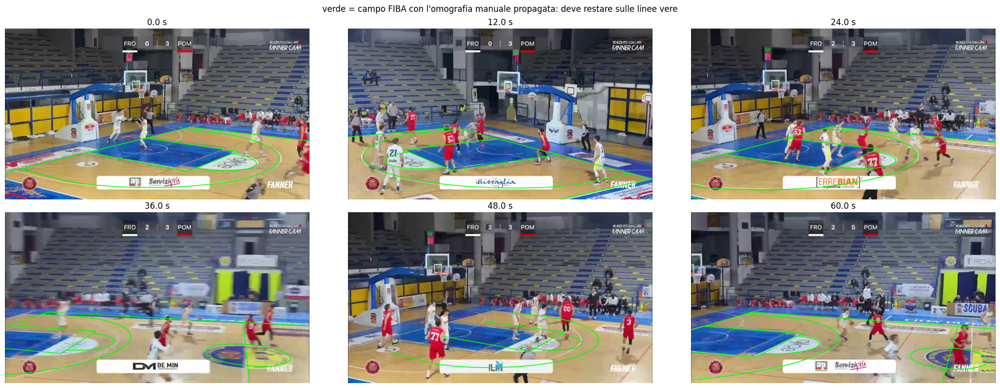

In [33]:
# 4M-2. Omografie dei fotogrammi chiave, movimento della camera e propagazione a tutta la clip
PUNTI_M = json.loads(PFILE.read_text()) if PFILE.is_file() else {}
H_KEY, KEY_ERR = {}, {}
for k, P in PUNTI_M.items():
    if len(P) < MIN_PUNTI: continue
    names = [n for n in P if n in LM]
    img = np.float32([P[n] for n in names]); wld = np.float32([m_to_ft(*LM[n]) for n in names])
    Hk, _ = cv2.findHomography(img, wld, 0)
    if Hk is None: continue
    res = np.linalg.norm(cv2.perspectiveTransform(img.reshape(-1, 1, 2), Hk).reshape(-1, 2) - wld, axis=1) * FT_TO_M
    H_KEY[int(k)] = Hk / Hk[2, 2]; KEY_ERR[int(k)] = round(float(np.median(res)) * 100, 1)
assert H_KEY, f'Nessun fotogramma chiave con almeno {MIN_PUNTI} punti: cliccali nella cella 4M'
print('fotogrammi chiave usati:', {k: f'{len(PUNTI_M[str(k)])} punti, residuo mediano {KEY_ERR[k]} cm' for k in sorted(H_KEY)})

# movimento della camera tra fotogrammi consecutivi, stimato solo sullo sfondo
ZONE_FISSE = [(0.00, 0.80, 0.16, 1.00), (0.25, 0.84, 0.72, 1.00), (0.78, 0.84, 1.00, 1.00),   # stemma, banner, FANNER in basso
              (0.30, 0.00, 0.70, 0.14), (0.80, 0.00, 1.00, 0.14)]                             # punteggio e FANNER CAM in alto
s_reg = REG_W / W_IMG; h_reg = int(round(H_IMG * s_reg))
base_mask = np.full((h_reg, REG_W), 255, np.uint8)
for a, b, c, d in ZONE_FISSE: base_mask[int(b * h_reg):int(d * h_reg), int(a * REG_W):int(c * REG_W)] = 0
S = np.diag([s_reg, s_reg, 1.0]); S_inv = np.linalg.inv(S)
G = [None] * N; n_inl = np.zeros(N, int)                         # G[t]: pixel del frame t -> pixel del frame t+1
prev, prev_mask = None, None
for fi, f in frames_iter(desc='movimento della camera'):
    g = cv2.cvtColor(cv2.resize(f, (REG_W, h_reg), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    m = base_mask.copy()
    for x1, y1, x2, y2, c in det_by.get(fi, np.zeros((0, 7)))[:, 1:6]:
        if c >= 0.2: m[max(0, int(y1 * s_reg) - 4):int(y2 * s_reg) + 4, max(0, int(x1 * s_reg) - 4):int(x2 * s_reg) + 4] = 0   # niente punti sulle persone
    if prev is not None and scene_of[fi] == scene_of[fi - 1]:
        p0 = cv2.goodFeaturesToTrack(prev, maxCorners=600, qualityLevel=0.01, minDistance=7, mask=prev_mask)
        if p0 is not None and len(p0) >= 30:
            p1, st, _ = cv2.calcOpticalFlowPyrLK(prev, g, p0, None, winSize=(21, 21), maxLevel=3)
            ok = st.ravel() == 1
            if ok.sum() >= 30:
                Gs, inl = cv2.findHomography(p0[ok], p1[ok], cv2.RANSAC, 1.5)
                if Gs is not None and inl is not None and inl.sum() >= 25:
                    G[fi - 1] = S_inv @ Gs @ S; n_inl[fi - 1] = int(inl.sum())
    prev, prev_mask = g, m

# propagazione: ogni frame prende l'omografia dal fotogramma chiave più vicino raggiungibile senza interruzioni
def propagate(k):
    Hp = {k: H_KEY[k]}
    H = H_KEY[k]
    for t in range(k + 1, N):                                       # in avanti: court = H_t-1 * inv(G_t-1) * x_t
        if G[t - 1] is None: break
        H = H @ np.linalg.inv(G[t - 1]); H = H / H[2, 2]; Hp[t] = H
    H = H_KEY[k]
    for t in range(k - 1, -1, -1):                                  # all'indietro: court = H_t+1 * G_t * x_t
        if G[t] is None: break
        H = H @ G[t]; H = H / H[2, 2]; Hp[t] = H
    return Hp
PROP = {k: propagate(k) for k in H_KEY}
hs_m = {}
for fi in range(N):
    cand = [k for k in PROP if fi in PROP[k]]
    if cand: hs_m[fi] = PROP[min(cand, key=lambda k: abs(k - fi))][fi]

# deriva: l'omografia propagata da un fotogramma chiave a un altro, confrontata con quella cliccata
drift = []
for a in PROP:
    for b in H_KEY:
        if a == b or b not in PROP[a]: continue
        P = PUNTI_M[str(b)]; names = [n for n in P if n in LM]
        img = np.float32([P[n] for n in names]).reshape(-1, 1, 2); wld = np.float32([m_to_ft(*LM[n]) for n in names])
        e = np.linalg.norm(cv2.perspectiveTransform(img, PROP[a][b]).reshape(-1, 2) - wld, axis=1) * FT_TO_M
        drift.append({'da_frame': a, 'a_frame': b, 'secondi': round(abs(b - a) / FPS, 1), 'errore_mediano_cm': round(float(np.median(e)) * 100, 1)})
DRIFT = pd.DataFrame(drift).sort_values('secondi') if drift else pd.DataFrame()
if len(DRIFT): display(DRIFT)
Q_M = {'fotogrammi_chiave': len(H_KEY), 'residuo_cm_chiave': KEY_ERR, 'frame_con_movimento_stimato_%': round(100 * float(np.mean([g is not None for g in G[:-1]])), 1),
       'inlier_mediani': int(np.median(n_inl[n_inl > 0])) if (n_inl > 0).any() else 0, 'frame_con_omografia_%': round(100 * len(hs_m) / N, 1),
       'deriva': DRIFT.to_dict('records') if len(DRIFT) else []}
(OUT / 'omografia_manuale_qualita.json').write_text(json.dumps(Q_M, indent=1, default=str)); print(json.dumps({k: v for k, v in Q_M.items() if k != 'deriva'}, indent=1))

# salvataggio nel formato letto dalla cella "4. Omografia"
from sports.basketball import League
_lg = (League.FIBA if LEAGUE_NAME == 'fiba' else League.NBA).value
(OUT / f'homographies_{tag}_{_lg}_manuale.json').write_text(json.dumps({str(k): v.tolist() for k, v in hs_m.items()}))

# controllo visivo: campo riproiettato su 6 fotogrammi
def court_lines_ft(n=60):
    L = [[(0, 0), (28, 0), (28, 15), (0, 15), (0, 0)], [(14, 0), (14, 15)]]
    for x0, s in [(0, 1), (28, -1)]:
        L.append([(x0, 5.05), (x0 + s * 5.8, 5.05), (x0 + s * 5.8, 9.95), (x0, 9.95)])
        a = np.linspace(-np.pi / 2, np.pi / 2, n); L.append(list(zip(x0 + s * (5.8 + 1.8 * np.cos(a)), 7.5 + 1.8 * np.sin(a))))
        a = np.linspace(-np.arcsin(6.6 / 6.75), np.arcsin(6.6 / 6.75), n)
        L.append([(x0, 0.9), (x0 + s * 2.99, 0.9)] + list(zip(x0 + s * (1.575 + 6.75 * np.cos(a)), 7.5 + 6.75 * np.sin(a))) + [(x0 + s * 2.99, 14.1), (x0, 14.1)])
    a = np.linspace(0, 2 * np.pi, 2 * n); L.append(list(zip(14 + 1.8 * np.cos(a), 7.5 + 1.8 * np.sin(a))))
    return [np.float32([m_to_ft(x, y) for x, y in l]) for l in L]
show = np.linspace(0, N - 1, 6).astype(int)
fig, ax = plt.subplots(2, 3, figsize=(21, 8))
for a_, (fi, f) in zip(ax.ravel(), frames_iter(wanted=set(show))):
    f = f.copy()
    if fi in hs_m:
        Hinv = np.linalg.inv(hs_m[fi])
        for l in court_lines_ft():
            p = cv2.perspectiveTransform(l.reshape(-1, 1, 2), Hinv).reshape(-1, 2)
            if np.isfinite(p).all() and np.abs(p).max() < 1e5: cv2.polylines(f, [p.astype(np.int32)], False, (0, 255, 0), 2, cv2.LINE_AA)
    a_.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); a_.set_title(f'{fi / FPS:.1f} s' + ('' if fi in hs_m else ' (senza omografia)')); a_.axis('off')
plt.suptitle('verde = campo FIBA con l\'omografia manuale propagata: deve restare sulle linee vere'); plt.tight_layout()
plt.savefig(OUT / 'omografia_manuale_controllo.png', dpi=110); plt.show()

## 4. Omografia (per scena) e posizioni sul campo

In [34]:
from sports import MeasurementUnit
from sports.basketball import CourtConfiguration, League, draw_court
LEAGUE = League.FIBA if LEAGUE_NAME == 'fiba' else League.NBA
court = CourtConfiguration(league=LEAGUE, measurement_unit=MeasurementUnit.FEET)
V = np.asarray(court.vertices, dtype=np.float32)
L_FT, W_FT = float(court.court_length), float(court.court_width)

hfile = OUT / (f'homographies_{tag}_{LEAGUE.value}' + ('_manuale' if globals().get('HOMO_MODE') == 'manuale' else '') + '.json')
if globals().get('HOMO_MODE') == 'manuale': assert hfile.is_file(), 'Omografia manuale non trovata: esegui prima le celle 4M e 4M-2'
print('omografia:', 'MANUALE con propagazione (celle 4M)' if globals().get('HOMO_MODE') == 'manuale' else 'keypoint automatici')
if hfile.is_file():
    hs = {int(k): np.asarray(v) for k, v in json.loads(hfile.read_text()).items()}
else:
    from inference import get_model
    try:
        from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
    except Exception:
        API_KEY = os.environ.get('ROBOFLOW_API_KEY') or __import__('getpass').getpass('API key Roboflow: ')
    court_model = get_model(model_id=COURT_MODEL_ID, api_key=API_KEY)
    hs = {}
    for fi, f in frames_iter(step=HOMO_EVERY, desc='omografia'):
        if excluded[fi]: continue
        res = court_model.infer(f, confidence=0.3)[0]
        if not res.predictions: continue
        pr = max(res.predictions, key=lambda p: p.confidence)
        pts = [p for p in pr.keypoints if p.confidence >= KP_CONF and 0 <= p.class_id < len(V)]   # unica modifica rispetto al notebook 15: soglia in configurazione
        if len(pts) >= 6:
            fwd, mask = cv2.findHomography(V[[p.class_id for p in pts]], np.float32([[p.x, p.y] for p in pts]), cv2.RANSAC, 8.0)
            if fwd is not None and mask is not None and mask.sum() >= 6:
                try: hs[fi] = np.linalg.inv(fwd)
                except np.linalg.LinAlgError: pass
    hfile.write_text(json.dumps({str(k): v.tolist() for k, v in hs.items()}))
# omografia del frame calcolato più vicino, ma solo nella stessa scena (mai attraverso un taglio)
Hs = [None] * N
for sc in np.unique(scene_of):
    fr_sc = np.where(scene_of == sc)[0]; ks = np.array([k for k in hs if scene_of[k] == sc])
    if len(ks) == 0: continue
    for fi in fr_sc: Hs[fi] = hs[int(ks[np.abs(ks - fi).argmin()])]
print(f'omografie valide: {len(hs)} | frame senza omografia: {sum(h is None for h in Hs)} su {N}')

def to_court(x, y, fi):
    H = Hs[int(fi)]
    if H is None: return (np.nan, np.nan)
    p = cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0]; return float(p[0]), float(p[1])
xy = [to_court(r.foot_x, r.foot_y, r.frame) if r.foot_ok else (np.nan, np.nan) for r in tracks.itertuples()]
tracks[['x_ft', 'y_ft']] = np.array(xy)
tracks[['x_raw', 'y_raw']] = tracks[['x_ft', 'y_ft']].values             # posizione non tagliata ai bordi: serve per riconoscere chi sta fuori dal campo
tracks.loc[~(tracks.x_ft.between(-3, L_FT + 3) & tracks.y_ft.between(-3, W_FT + 3)), ['x_ft', 'y_ft']] = np.nan
W_SM = max(3, int(round(FPS / 2)) | 1)
tracks = tracks.sort_values(['track_id', 'frame']).reset_index(drop=True)
tracks[['xs_ft', 'ys_ft']] = tracks.groupby('track_id')[['x_ft', 'y_ft']].transform(
    lambda s: s.rolling(W_SM, center=True, min_periods=1).median().rolling(5, center=True, min_periods=1).mean())
v = tracks[tracks.x_raw.notna()]
outside = ~(v.x_raw.between(-OUT_MARGIN_FT, L_FT + OUT_MARGIN_FT) & v.y_raw.between(-OUT_MARGIN_FT, W_FT + OUT_MARGIN_FT))
frac_out = outside.groupby(v.track_id).mean(); n_pos = v.groupby('track_id').size()
fuori = [int(t) for t in frac_out.index if frac_out[t] >= OUT_FRAC and n_pos[t] >= 10]
tracks = tracks[~tracks.track_id.isin(fuori)].reset_index(drop=True)
for t in fuori: team_of[t] = -1
print('persone fuori dal campo (panchina, staff, tifosi) eliminate:', len(fuori), fuori[:20])
tracks.to_csv(OUT / 'tracks_court.csv', index=False)
print('posizioni sul campo valide:', int(tracks.xs_ft.notna().sum()), 'su', len(tracks))

omografia: MANUALE con propagazione (celle 4M)
omografie valide: 1800 | frame senza omografia: 0 su 1800
persone fuori dal campo (panchina, staff, tifosi) eliminate: 0 []
posizioni sul campo valide: 12028 su 12687


## 4b. Punteggio dal tabellone (per distinguere tiri segnati e sbagliati)

Il detector riconosce male "ball-in-basket" (in az1 0,69 di confidenza su tiri sbagliati, in az4 quasi mai). Si usa invece il **tabellone**: quando le cifre del punteggio di una squadra cambiano e restano cambiate per 1,5 s, quella squadra ha segnato. Non serve leggere i numeri (l'OCR confonde 3, 8 e 9): basta accorgersi che l'immagine delle cifre è cambiata. Funziona solo quando il tabellone è visibile (non nei replay e nei primi piani senza grafica).

In [35]:
def rel_crop(f, box):
    x1, y1, x2, y2 = box; return f[int(y1 * H_IMG):int(y2 * H_IMG), int(x1 * W_IMG):int(x2 * W_IMG)]
def digits(c):
    g = cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2GRAY), (64, 40))
    _, b = cv2.threshold(g, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return (1 - b if b.mean() > .5 else b).astype(np.float32)
def sdiff(a, b, r=4):
    # differenza tra due immagini di cifre, tollerando piccoli spostamenti del tabellone (qualche pixel)
    return min(np.abs(np.roll(np.roll(a, dy, 0), dx, 1) - b)[r:-r, r:-r].mean() for dy in range(-r, r + 1) for dx in range(-r, r + 1))
SB_STEP = 3; sb_f, sb_logo, sb_dig = [], [], {k: [] for k in SCORE_BOXES}
for fi, f in frames_iter(step=SB_STEP, desc='tabellone'):
    sb_f.append(fi); sb_logo.append(cv2.resize(cv2.cvtColor(rel_crop(f, SCORE_LOGO), cv2.COLOR_BGR2GRAY), (64, 24)).astype(np.float32) / 255)
    for k, b in SCORE_BOXES.items(): sb_dig[k].append(digits(rel_crop(f, b)))
tmpl = np.median(np.stack(sb_logo), 0); sb_vis = np.array([np.abs(l - tmpl).mean() < 0.2 for l in sb_logo])
score_changes = []                                             # (frame, lato)
H_SB = int(round(SCORE_HOLD_S * FPS / SB_STEP))
for k in SCORE_BOXES:
    # v3: il punteggio di riferimento è la MAGGIORANZA dei pixel su 1,5 s stabili (non un singolo frame):
    # niente falsi canestri dall'animazione d'ingresso del tabellone o dal rumore di compressione
    seq = [(fi, m) for fi, m, vis in zip(sb_f, sb_dig[k], sb_vis) if vis and not excluded[fi]]   # frame senza tabellone: saltati
    ref, i = None, 0
    while i < len(seq):
        win = [m for _, m in seq[i:i + H_SB]]
        if ref is None:                                            # primo punteggio stabile = riferimento
            if len(win) < H_SB: break
            maj = (np.mean(win, 0) > 0.5).astype(np.float32)
            if np.mean([sdiff(m, maj) <= SCORE_THR for m in win]) >= SCORE_FRAC: ref = maj; i += H_SB
            else: i += 1
            continue
        if sdiff(seq[i][1], ref) <= SCORE_THR: i += 1; continue
        start = seq[i][0]
        if len(win) < H_SB:                                        # canestro proprio alla fine della clip
            if len(win) * SB_STEP >= 0.3 * FPS and np.mean([sdiff(m, ref) > SCORE_THR for m in win]) >= SCORE_FRAC: score_changes.append((start, k))
            break
        maj = (np.mean(win, 0) > 0.5).astype(np.float32)
        if (np.mean([sdiff(m, ref) > SCORE_THR for m in win]) >= SCORE_FRAC and np.mean([sdiff(m, maj) <= SCORE_THR for m in win]) >= SCORE_FRAC
                and sdiff(maj, ref) > SCORE_THR):                  # nuovo punteggio diverso dal vecchio e stabile per 1,5 s
            if not (score_changes and score_changes[-1][1] == k and start - score_changes[-1][0] < 4 * FPS):   # animazione in due tempi = un solo canestro
                score_changes.append((start, k))
            ref = maj; i += H_SB
        else: i += 1
play = ~excluded[np.array(sb_f)]                                 # visibilità calcolata solo sui tratti di gioco (non su pause e replay esclusi)
vis_pct = float(sb_vis[play].mean()) if play.any() else 0.0
score_changes.sort(); SCORE_OK = vis_pct >= 0.5
print(f'tabellone visibile nel {100 * vis_pct:.0f}% dei frame di gioco | canestri letti dal tabellone:',
      [(round(f / FPS + START_S, 1), k) for f, k in score_changes], '' if SCORE_OK else '(tabellone poco visibile: si usa ball-in-basket)')

tabellone:   0%|          | 0/1800 [00:00<?, ?it/s]

tabellone visibile nel 100% dei frame di gioco | canestri letti dal tabellone: [(15.9, 'L'), (55.1, 'R')] 


## 5. Palla: tracker di Kalman

Per ogni frame si considerano tutti i candidati `ball` (≥ `BALL_MIN_CONF`). Se la palla è agganciata, si accetta solo il candidato più vicino alla posizione **prevista** dal moto (entro un raggio che cresce con i frame di assenza); se nessun candidato è plausibile la palla resta "prevista" per al massimo `BALL_MAX_MISS` frame, poi è persa. Si riaggancia solo con una detection sicura (≥ `BALL_INIT_CONF`). Il tracker riparte a ogni taglio di scena.

In [36]:
def new_kf(x, y):
    kf = cv2.KalmanFilter(4, 2)
    kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32)
    kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)
    kf.processNoiseCov = np.diag([1, 1, 8, 8]).astype(np.float32)
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 4
    kf.statePost = np.array([[x], [y], [0], [0]], np.float32); kf.errorCovPost = np.eye(4, dtype=np.float32) * 50
    return kf

bc = det[(det['name'] == 'ball') & (det.conf >= BALL_MIN_CONF)].copy()
bc['cx'] = (bc.x1 + bc.x2) / 2; bc['cy'] = (bc.y1 + bc.y2) / 2
cand_by = {f: g[['cx', 'cy', 'conf']].values for f, g in bc.groupby('frame')}
acc = np.full((N, 2), np.nan); kf, miss, reinit = None, 0, 0
for fi in range(N):
    if excluded[fi] or (fi > 0 and scene_of[fi] != scene_of[fi - 1]): kf, miss = None, 0
    if excluded[fi]: continue
    C = cand_by.get(fi, np.zeros((0, 3)))
    if kf is not None:
        pred = kf.predict()[:2].ravel()
        if len(C):
            d = np.hypot(C[:, 0] - pred[0], C[:, 1] - pred[1]); j = int(d.argmin())
            if d[j] <= BALL_GATE * W_IMG * (1 + miss):
                kf.correct(C[j, :2].astype(np.float32).reshape(2, 1)); acc[fi] = C[j, :2]; miss = 0; continue
        miss += 1
        if miss > BALL_MAX_MISS: kf, miss = None, 0
    if kf is None and len(C) and C[:, 2].max() >= BALL_INIT_CONF:
        j = int(C[:, 2].argmax()); kf = new_kf(*C[j, :2]); acc[fi] = C[j, :2]; reinit += 1
ball = pd.DataFrame(acc, columns=['bx', 'by'])
filled = ball.copy()
for sc in np.unique(scene_of):                            # riempimento dei buchi brevi, solo dentro la scena
    m = scene_of == sc
    filled.loc[m] = ball.loc[m].interpolate(limit=BALL_FILL, limit_area='inside')
ball = filled
valid_frames = (~excluded).sum()
print(f'palla: candidati in {len(cand_by) / valid_frames:.0%} dei frame | accettata in {np.isfinite(acc[:, 0]).sum() / valid_frames:.0%} '
      f'| dopo riempimento {ball.bx.notna().sum() / valid_frames:.0%} | riagganci: {reinit}')

palla: candidati in 49% dei frame | accettata in 28% | dopo riempimento 52% | riagganci: 33


## 6. Possesso ed eventi automatici (regole del notebook 14 v2, mai attraverso un taglio di scena)

In [37]:
by_frame = dict(tuple(tracks[tracks.team >= 0].groupby('frame')))
raw = np.full(N, -1); last_team, last_fi = -1, -10**9
for fi in range(N):
    if fi > 0 and scene_of[fi] != scene_of[fi - 1]: last_team = -1
    g = by_frame.get(fi)
    if g is None or excluded[fi]: continue
    p = g[(g.cls == 'player-in-possession') & (g.cls_conf >= POSS_CONF)]
    bx, by = ball.bx[fi], ball.by[fi]
    if len(p):
        if len(p) > 1 and not np.isnan(bx):
            p = p.assign(d=np.hypot((p.x1 + p.x2) / 2 - bx, (p.y1 + p.y2) / 2 - by)).sort_values('d')
        raw[fi] = int(p.track_id.iloc[0]); last_team, last_fi = int(p.team.iloc[0]), fi; continue
    if np.isnan(bx): continue
    h = (g.y2 - g.y1).values
    dx = np.maximum.reduce([g.x1.values - bx, np.zeros(len(g)), bx - g.x2.values])
    dy = np.maximum.reduce([g.y1.values - by, np.zeros(len(g)), by - g.y2.values])
    d = np.hypot(dx, dy) / np.maximum(h, 1); k = int(d.argmin())
    if d[k] > POSS_RADIUS: continue
    near = np.where((d <= d[k] + POSS_TIE) & (g.team.values == last_team))[0]
    if len(near) and g.team.values[k] != last_team and fi - last_fi <= 0.3 * FPS: k = int(near[d[near].argmin()])   # contesa con un avversario subito dopo un possesso: vince il compagno
    raw[fi] = int(g.track_id.values[k]); last_team, last_fi = int(g.team.values[k]), fi
poss = np.full(N, -1); cur, cand, cnt, cand_start, lost = -1, -1, 0, 0, 0
for fi in range(N):
    if fi > 0 and scene_of[fi] != scene_of[fi - 1]: cur, cand, cnt, lost = -1, -1, 0, 0
    r = raw[fi]
    if r != cur:                                            # il portatore non è più confermato (palla persa o vicina a un altro)
        lost += 1
        if lost > POSS_LOST: cur = -1
    if r != -1:
        if r == cur: cand, cnt, lost = -1, 0, 0
        else:
            if r == cand: cnt += 1
            else: cand, cnt, cand_start = r, 1, fi
            if cnt >= POSS_MIN: cur = cand; poss[cand_start:fi] = cur; cand, cnt = -1, 0
    poss[fi] = cur
segs, s = [], None
for fi in range(N + 1):
    v = poss[fi] if fi < N else -2
    if s is not None and (v != s[0] or (fi < N and scene_of[fi] != scene_of[s[1]])):
        segs.append({'track_id': s[0], 'start': s[1], 'end': fi - 1}); s = None
    if s is None and fi < N and v >= 0: s = (v, fi)
sg = pd.DataFrame(segs, columns=['track_id', 'start', 'end'])
sg['team'] = sg.track_id.map(team_of).fillna(-1).astype(int); sg = sg[sg.team >= 0]
n_raw = len(sg); changed = True
while changed and len(sg):
    changed = False
    short = sg[(sg.end - sg.start + 1) / FPS < MIN_SEG_S]
    if len(short): sg = sg.drop(index=short.index); changed = True
    sg = sg.sort_values('start').reset_index(drop=True); merged = []
    for r in sg.to_dict('records'):
        if merged and merged[-1]['track_id'] == r['track_id'] and (r['start'] - merged[-1]['end']) / FPS <= PASS_MAX_GAP_S:
            merged[-1]['end'] = r['end']; changed = True
        else: merged.append(dict(r))
    sg = pd.DataFrame(merged, columns=['track_id', 'start', 'end', 'team'])
if len(sg):
    sg['team_run'] = ((sg.team != sg.team.shift()) | (scene_of[sg.start.values] != scene_of[sg.start.shift().fillna(0).astype(int).values])).cumsum()
    run_dur = (sg.groupby('team_run').end.max() - sg.groupby('team_run').start.min() + 1) / FPS
    sg['team_run_s'] = sg.team_run.map(run_dur)
    # v3: possesso di squadra anche attraverso i tagli di scena (stessa squadra, buco <= STEAL_GAP_S): serve alle palle rubate
    sg['team_poss'] = ((sg.team != sg.team.shift()) | ((sg.start - sg.end.shift().fillna(-1e9)) / FPS > STEAL_GAP_S)).cumsum()
    poss_dur = (sg.groupby('team_poss').end.max() - sg.groupby('team_poss').start.min() + 1) / FPS
    sg['team_poss_s'] = sg.team_poss.map(poss_dur)
segs = sg
poss = np.full(N, -1)
for r in segs.itertuples(): poss[int(r.start):int(r.end) + 1] = int(r.track_id)
print(f'possesso: {n_raw} segmenti grezzi -> {len(segs)} dopo la pulizia')

def pos_at(tid, fi, win=60):
    g = tracks[(tracks.track_id == tid) & tracks.xs_ft.notna() & tracks.frame.between(fi - win, fi + win)]
    if not len(g): return (np.nan, np.nan)
    r = g.iloc[(g.frame - fi).abs().argmin()]; return float(r.xs_ft), float(r.ys_ft)
R3 = court.three_point_arc_radius; STRAIGHT = court.straight_section_three_point_line
CORNER = W_FT / 2 - court.sideline_to_three_point_line
BASKETS = [(court.baseline_to_rim_center, W_FT / 2), (L_FT - court.baseline_to_rim_center, W_FT / 2)]
def shot_value(x, y):
    if np.isnan(x): return np.nan, np.nan
    bx, byy = min(BASKETS, key=lambda b: abs(b[0] - x)); d = float(np.hypot(x - bx, y - byy))
    from_baseline = x if bx < L_FT / 2 else L_FT - x
    three = abs(y - byy) >= CORNER if from_baseline <= STRAIGHT else d >= R3
    return (3 if three else 2), d * FT_TO_M

sh = tracks[tracks.cls.isin(['player-jump-shot', 'player-layup-dunk']) & (tracks.cls_conf >= 0.3) & (tracks.team >= 0)]
cand_s = []
for tid, g in sh.groupby('track_id'):
    f = g.frame.values
    for r in np.split(f, np.where(np.diff(f) > 3)[0] + 1):
        if len(r) >= SHOT_MIN_FRAMES: cand_s.append((int(r[0]), int(tid), len(r), None))
# tiri dalla traiettoria della palla (oltre alle classi "tiro" del detector)
rim_by = {f: g[['x1', 'y1', 'x2', 'y2']].values for f, g in det[(det['name'] == 'rim') & (det.conf >= RIM_CONF)].groupby('frame')}
rim_frames = np.array(sorted(rim_by)); near_rim = np.zeros(N, bool)
for fi in range(N):
    if excluded[fi] or np.isnan(ball.bx[fi]) or not len(rim_frames): continue
    k = int(rim_frames[np.abs(rim_frames - fi).argmin()])
    if abs(k - fi) > 5 or scene_of[k] != scene_of[fi]: continue
    for x1, y1, x2, y2 in rim_by[k]:
        w = x2 - x1; h = max(y2 - y1, 0.3 * w)
        if x1 - 0.5 * w <= ball.bx[fi] <= x2 + 0.5 * w and y1 - 1.5 * h <= ball.by[fi] <= y2 + 0.3 * h:
            near_rim[fi] = True; break
def release_frame(c, max_back_s=2.5):
    # rilascio del tiro dalla traiettoria: dal ferro si torna indietro fino al punto più alto del volo,
    # poi si continua finché la palla è di nuovo dentro il box di un giocatore (le mani del tiratore)
    fs = [k for k in range(c, max(-1, c - int(max_back_s * FPS)), -1) if not np.isnan(acc[k, 0]) and scene_of[k] == scene_of[c]]
    if len(fs) < 3: return None
    apex = int(np.argmin([acc[k, 1] for k in fs]))
    for k in fs[apex:]:
        g = by_frame.get(k)
        if g is None: continue
        bx, by = acc[k]
        if ((g.x1 <= bx) & (bx <= g.x2) & (g.y1 <= by) & (by <= g.y2)).any(): return k
    return None
idx = np.where(near_rim)[0]; n_rim = 0
for run in (np.split(idx, np.where(np.diff(idx) > 5)[0] + 1) if len(idx) else []):
    if len(run) < RIM_MIN_FRAMES: continue
    c = int(run[0])
    prev = segs[(segs.start <= c + 0.3 * FPS) & (segs.end >= c - SHOT_LOOKBACK_S * FPS)]   # anche subito dopo un cambio di telecamera
    if not len(prev): continue
    r = prev.sort_values('start').iloc[-1]
    before = prev[(prev.end < c - 3) & (prev.start.apply(lambda f: scene_of[int(f)] == scene_of[c]))]
    if len(before) and r.start > c - 3: r = before.sort_values('end').iloc[-1]   # chi riceve la palla sotto canestro mentre arriva non è il tiratore
    f0w = max(0, min(c, int(r.end)) - int(1.5 * FPS))
    done = set(segs.track_id[(segs.end < r.start) & (segs.end >= f0w)].astype(int)) - {int(r.track_id)}   # chi ha già passato la palla non è il tiratore
    w = [int(raw[k]) for k in range(f0w, min(c, int(r.end)) + 1) if raw[k] >= 0 and scene_of[k] == scene_of[int(r.start)]
         and team_of.get(int(raw[k]), -1) == r.team and int(raw[k]) not in done]
    shooter = max(set(w), key=w.count) if w else int(r.track_id)      # tiratore = chi ha avuto più a lungo la palla nell'ultimo 1,5 s (stessa inquadratura)
    f_shot = max(int(r.start), min(int(r.end), c))
    rel = release_frame(c)
    if rel is not None and rel < f_shot:                           # il rilascio dalla traiettoria vince: tiratore = chi aveva la palla prima del rilascio
        w = [int(raw[k]) for k in range(max(0, rel - int(1.5 * FPS)), rel + 1) if raw[k] >= 0 and scene_of[k] == scene_of[rel]]
        if w: shooter, f_shot = max(set(w), key=w.count), rel
    cand_s.append((f_shot, shooter, 100, c)); n_rim += 1
n_cls = sum(1 for c in cand_s if c[2] < 100)
cand_s = [c for c in cand_s if c[2] >= 100 or near_rim[c[0]:c[0] + int(SHOT_WINDOW_S * FPS)].any()]   # un tiro esiste solo se la palla arriva al ferro
print('tiri riconosciuti dalla traiettoria verso il ferro:', n_rim, '| candidati dalla posa scartati perché la palla non arriva al ferro:', n_cls - sum(1 for c in cand_s if c[2] < 100))

def ball_free(f0, f1):
    # frame in cui la palla (vista davvero, non riempita) è fuori da tutti i giocatori
    n = 0
    for fi in range(max(0, f0 - 2), min(N, f1 + 3)):
        bx, by = acc[fi]
        if np.isnan(bx): continue
        g = by_frame.get(fi)
        if g is None: n += 1; continue
        mw = 0.1 * (g.x2 - g.x1)
        n += not ((g.x1 - mw <= bx) & (bx <= g.x2 + mw) & (g.y1 <= by) & (by <= g.y2)).any()
    return n

def exchange_ok(a, b):
    # passaggio / recupero plausibile: chi riceve era già visibile prima, e la palla non è sparita troppo a lungo nel mezzo
    born = tracks.frame[tracks.track_id == b.track_id].min()
    if born > b.start - PASS_SEEN_BEFORE_S * FPS: return False
    seen = np.isfinite(acc[int(a.end):int(b.start) + 1, 0])
    blind = max((len(r) for r in ''.join('1' if not v else '0' for v in seen).split('0')), default=0)
    return blind <= PASS_MAX_BLIND_S * FPS

shots = []
for f0, tid, n, c_rim in sorted(cand_s, key=lambda t: t[0]):
    if shots and f0 - shots[-1]['frame'] < 1.5 * FPS:
        if n > shots[-1]['_n']: shots[-1].update(frame=f0, track_id=tid, _n=n, c=c_rim)
        continue
    shots.append({'frame': f0, 'track_id': tid, '_n': n, 'c': c_rim})
def last_touch(tid, c):
    # ultimo frame prima dell'arrivo al ferro in cui la palla è nelle mani del tiratore = RILASCIO
    for k in range(c, max(-1, c - int(2.5 * FPS)), -1):
        if raw[k] == tid and scene_of[k] == scene_of[c]: return k
    return None
def through_rim(f0):
    # la palla, entro SHOT_WINDOW_S, viene vista sotto il ferro e dentro la sua larghezza (passa nella retina)
    for fi in range(f0, min(N, f0 + int(SHOT_WINDOW_S * FPS))):
        bx, by = acc[fi]
        if np.isnan(bx) or not len(rim_frames): continue
        k = int(rim_frames[np.abs(rim_frames - fi).argmin()])
        if abs(k - fi) > 5: continue
        for x1, y1, x2, y2 in rim_by[k]:
            w = x2 - x1
            if x1 + 0.1 * w <= bx <= x2 - 0.1 * w and y2 <= by <= y2 + 1.2 * w: return True
    return False
def shot_pos(tid, f):
    # posizione del tiro allo STACCO: nel salto il box si alza e la proiezione sul campo si sposta verso il canestro,
    # quindi si usa la mediana delle posizioni (non smussate) tra 0,7 e 0,25 s prima del rilascio, quando i piedi sono a terra
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f - int(0.7 * FPS), f - int(0.25 * FPS)) & tracks.x_ft.notna()]
    return (float(g.x_ft.median()), float(g.y_ft.median())) if len(g) >= 3 else pos_at(tid, f)
made_f = np.sort(det[(det['name'] == 'ball-in-basket') & (det.conf >= MADE_CONF)].frame.unique())
def ball_near(tid, f, before_s=0.7, after_s=0.3):
    # la palla (vista davvero) è nelle mani o sopra la testa del giocatore attorno al frame f
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f - int(before_s * FPS), f + int(after_s * FPS))]
    for r in g.itertuples():
        bx, by = acc[int(r.frame)]
        if np.isnan(bx): continue
        w, h = r.x2 - r.x1, r.y2 - r.y1
        if r.x1 - 0.5 * w <= bx <= r.x2 + 0.5 * w and r.y1 - 0.5 * h <= by <= r.y2: return True
    return False
events = []
for s in shots:
    s['team'] = team_of.get(s['track_id'], -1)
    if s['c'] is None and s['_n'] < 100 and not ball_near(s['track_id'], s['frame']):
        # v3: tiro visto solo dalla posa ("player-jump-shot") ma palla mai vista vicino a quel giocatore: il tiratore vero non è rilevato.
        # Meglio "tiratore non rilevato" che il compagno (o l'avversario) più vicino: squadra = chi aveva l'ultimo possesso prima del tiro
        pv = segs[segs.end <= s['frame']]
        if len(pv): s['team'] = int(pv.team.iloc[-1])
        s['track_id'] = -1
    w = made_f[(made_f >= s['frame']) & (made_f <= s['frame'] + SHOT_WINDOW_S * FPS) & (scene_of[made_f] == scene_of[s['frame']])]
    made = len(w) >= MADE_MIN_FRAMES
    if made and MADE_THROUGH: made = through_rim(s['frame'])
    if SCORE_OK:                                                  # il tabellone decide se è canestro e DI QUALE SQUADRA
        sides = [k for f, k in score_changes if s['frame'] <= f <= s['frame'] + MADE_WINDOW_S * FPS]
        made = bool(sides)
        if made:
            t_made = next((t for t, k in SCORE_SIDE.items() if k == sides[0]), -1)
            if s['team'] != t_made:                                # tiratore della squadra sbagliata (es. difensore vicino alla palla): si sceglie nella squadra che ha segnato
                f0 = s['frame']; w = [int(raw[k]) for k in range(max(0, f0 - int(1.5 * FPS)), f0 + 1) if raw[k] >= 0 and team_of.get(int(raw[k]), -1) == t_made]
                if not w and f0 in by_frame and not np.isnan(acc[f0, 0]):
                    g = by_frame[f0]; g = g[g.team == t_made]
                    if len(g): w = [int(g.iloc[np.hypot((g.x1 + g.x2) / 2 - acc[f0, 0], (g.y1 + g.y2) / 2 - acc[f0, 1]).argmin()].track_id)]
                if w: s['track_id'] = max(set(w), key=w.count)
                s['team'] = t_made
    if s['c'] is not None:                                        # il tiro avviene quando la palla lascia la mano, non quando arriva al ferro
        lt = last_touch(s['track_id'], s['c'])
        if lt is not None: s['frame'] = lt
        born = tracks.frame[tracks.track_id == s['track_id']].min()   # tiratore "nato" con un cambio di telecamera proprio durante il tiro:
        cut = max((c0 for c0 in cuts if born - 3 <= c0 <= s['frame']), default=None)   # il rilascio è nell'inquadratura precedente
        if cut is not None and s['frame'] - born < 0.5 * FPS:
            pv = segs[(segs.end >= cut - 6) & (segs.end < cut) & (segs.team == team_of.get(s['track_id'], -1))]
            if len(pv): s['track_id'], s['frame'] = int(pv.track_id.iloc[-1]), int(pv.end.iloc[-1])
    s['made'] = made
    if s['track_id'] >= 0: s['team'] = team_of.get(s['track_id'], s['team'])
    x, y = shot_pos(s['track_id'], s['frame']) if s['track_id'] >= 0 else (np.nan, np.nan); val, dist = shot_value(x, y)
    events.append({'tipo': 'tiro_segnato' if made else 'tiro_sbagliato', 'frame': s['frame'], 'da': s['track_id'] if s['track_id'] >= 0 else np.nan, 'a': np.nan,
                   'team': s['team'], 'x_ft': x, 'y_ft': y, 'x2_ft': np.nan, 'y2_ft': np.nan,
                   'dettaglio': f'da {val} punti, {dist:.1f} m' if not np.isnan(dist) else ('tiratore non rilevato' if s['track_id'] < 0 else '')})
for f, k in (score_changes if SCORE_OK else []):              # canestro letto dal tabellone ma nessun tiro trovato (palla persa in volo): il tiro c'è comunque
    if excluded[min(f, N - 1)] or any(s['made'] and s['frame'] <= f <= s['frame'] + MADE_WINDOW_S * FPS for s in shots): continue
    t_made = next((t for t, kk in SCORE_SIDE.items() if kk == k), -1)
    pv = segs[(segs.end <= f - 0.5 * FPS) & (segs.end >= f - MADE_WINDOW_S * FPS)].sort_values('end')   # possesso confermato finito prima del volo (almeno 0,5 s)
    if not len(pv): continue
    last = pv.iloc[-1]; same = pv[pv.team == t_made]
    sh_seg = same.iloc[-1] if len(same) else last                  # tiratore = ultimo giocatore DELLA SQUADRA CHE HA SEGNATO visto con la palla
    tid, fr = int(sh_seg.track_id), int(last.end)                  # tempo = ultimo istante in cui la palla era in mano a qualcuno, prima del volo
    x, y = shot_pos(tid, int(sh_seg.end)); val, dist = shot_value(x, y)   # posizione = dove il tiratore è stato visto per l'ultima volta
    shots.append({'frame': fr, 'track_id': tid, '_n': 0, 'c': None, 'made': True, 'f_score': int(f), 'team': t_made})
    events.append({'tipo': 'tiro_segnato', 'frame': fr, 'da': tid, 'a': np.nan, 'team': t_made, 'x_ft': x, 'y_ft': y, 'x2_ft': np.nan, 'y2_ft': np.nan,
                   'dettaglio': (f'da {val} punti, {dist:.1f} m, ' if not np.isnan(dist) else '') + 'dal tabellone'})
shot_frames = np.array([s['frame'] for s in shots]); shot_made = {s['frame']: s['made'] for s in shots}
shot_team = {s['frame']: s.get('team', team_of.get(s['track_id'], -1)) for s in shots}
for e in events:
    if e['tipo'] == 'tiro_segnato': shot_team[e['frame']] = e['team']          # la squadra del canestro è quella del tabellone
# palla in volo (dal rilascio al ferro) e, dopo un canestro, palla nella retina per 0,8 s: nessun possesso in quegli istanti
flights = [(s['frame'], s['c'] + (int(0.8 * FPS) if s['made'] else int(0.3 * FPS))) for s in shots if s['c'] is not None]
flights += [(s['frame'], s['f_score']) for s in shots if s.get('f_score') is not None]   # v3: canestro dal tabellone: dal rilascio al cambio del punteggio la palla è in volo o nella retina
if flights and len(segs):
    in_flight = segs.start.apply(lambda f: any(a + 3 < f <= b for a, b in flights))
    segs = segs[~in_flight].reset_index(drop=True)
inbound = set(); inbound_solo = set()                            # dopo un canestro: il primo cambio di mano nella squadra che rimette è sempre un passaggio (rimessa)
for s_ in shots:
    ref = s_['c'] if s_['c'] is not None else s_.get('f_score')   # v3: anche dopo i canestri letti solo dal tabellone
    if not s_['made'] or ref is None: continue
    t_def = 1 - shot_team[s_['frame']] if shot_team[s_['frame']] in (0, 1) else -1
    nxt = [j for j in range(len(segs)) if segs.start.iloc[j] > ref and segs.team.iloc[j] == t_def and segs.start.iloc[j] - ref <= 8 * FPS]
    if nxt:
        j = nxt[0]
        if (j + 1 < len(segs) and segs.team.iloc[j + 1] == t_def and segs.track_id.iloc[j + 1] != segs.track_id.iloc[j]
                and scene_of[int(segs.start.iloc[j + 1])] == scene_of[int(segs.end.iloc[j])]): inbound.add(j)
        else:                                                      # v3: chi ha la palla è FUORI dal campo (dietro la linea di fondo o laterale) = chi rimette,
            x_, y_ = pos_at(segs.track_id.iloc[j], segs.end.iloc[j])   # anche se chi riceve non è rilevato: la rimessa è comunque un passaggio
            if not np.isnan(x_) and (x_ < 0 or x_ > L_FT or y_ < 0 or y_ > W_FT): inbound_solo.add(j)
def keeps_ball(j):
    # durata del possesso della squadra del segmento j, dal suo inizio fino al cambio di squadra
    t, e = segs.team.iloc[j], segs.end.iloc[j]
    for k in range(j + 1, len(segs)):
        if segs.team.iloc[k] != t or scene_of[int(segs.start.iloc[k])] != scene_of[int(segs.start.iloc[j])]: break
        e = segs.end.iloc[k]
    return (e - segs.start.iloc[j] + 1) / FPS
def held_frac(tid, f0, f1):
    # quota di frame (con palla vista) in cui la palla è dentro il box del giocatore
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f0, f1)].set_index('frame')
    n = k = 0
    for fi in g.index:
        bx, by = acc[fi]
        if np.isnan(bx): continue
        n += 1; r = g.loc[fi]; k += (r.x1 <= bx <= r.x2) and (r.y1 <= by <= r.y2)
    return k / n if n else 0.0
def held_n(tid, f0, f1):
    # numero di frame (con palla vista davvero) in cui la palla è DENTRO il box del giocatore
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f0, f1)]
    return sum(1 for r in g.itertuples() if not np.isnan(acc[int(r.frame), 0]) and r.x1 <= acc[int(r.frame), 0] <= r.x2 and r.y1 <= acc[int(r.frame), 1] <= r.y2)
def team_held(j):
    # palla in mano alla squadra del segmento j, su tutto il suo possesso di squadra
    m = segs[segs.team_poss == segs.team_poss.iloc[j]]
    return sum(held_n(int(r.track_id), int(r.start), int(r.end)) for r in m.itertuples())
def scores_next(j):
    # v3: dopo il segmento j la sua squadra tiene la palla (nessun possesso avversario) fino a un PROPRIO canestro: il cambio di possesso è confermato
    t, f0 = segs.team.iloc[j], segs.start.iloc[j]
    nxt = sorted([s_ for s_ in shots if s_['frame'] >= f0], key=lambda s_: s_['frame'])
    if not nxt or not nxt[0]['made'] or shot_team[nxt[0]['frame']] != t: return False
    return bool((segs[(segs.start > f0) & (segs.start < nxt[0]['frame'])].team == t).all())
skip_until = -1
for i in range(len(segs) - 1):
    if i < skip_until: continue
    a, b = segs.iloc[i], segs.iloc[i + 1]
    gap = (b.start - a.end) / FPS
    between = shot_frames[(shot_frames >= a.start) & (shot_frames <= b.start)] if len(shot_frames) else []
    cross = scene_of[int(a.end)] != scene_of[int(b.start)]       # cambio di telecamera in mezzo
    if a.track_id == b.track_id: continue
    if len(between):                                              # dopo un tiro: il rimbalzo si cerca anche dopo un cambio di telecamera
        if (b.start - max(a.end, between[-1])) / FPS > REB_MAX_GAP_S: continue   # v3: tempo contato dal TIRO (il tiratore può non essere più tracciato)
    elif gap > PASS_MAX_GAP_S or cross: continue                  # passaggi e recuperi solo dentro la stessa inquadratura
    xa, ya = pos_at(a.track_id, a.end); xb, yb = pos_at(b.track_id, b.start)
    base = {'frame': int(b.start), 'da': int(a.track_id), 'a': int(b.track_id), 'team': int(b.team), 'x_ft': xa, 'y_ft': ya, 'x2_ft': xb, 'y2_ft': yb}
    if len(between):
        if not shot_made[int(between[-1])]:
            j = i + 1                                              # chi tocca la palla per un attimo non è il rimbalzista
            while (j + 1 < len(segs) and keeps_ball(j) < REB_MIN_S and segs.team.iloc[j + 1] != segs.team.iloc[j]
                   and (segs.start.iloc[j + 1] - between[-1]) / FPS <= 3.0): j += 1
            rb = segs.iloc[j]; xr, yr = pos_at(rb.track_id, rb.start); skip_until = j
            if held_frac(int(rb.track_id), int(rb.start), int(rb.end)) < REB_HOLD_FRAC: continue   # palla solo "vicina" (prospettiva): niente rimbalzo
            events.append({**base, 'frame': int(rb.start), 'a': int(rb.track_id), 'team': int(rb.team), 'x_ft': xr, 'y_ft': yr, 'x2_ft': np.nan, 'y2_ft': np.nan,
                           'tipo': 'rimbalzo', 'dettaglio': 'offensivo' if shot_team[int(between[-1])] == rb.team else 'difensivo'})
        continue
    if a.team == b.team and i in inbound:                         # rimessa: chi rimette non può palleggiare, quindi è per forza un passaggio
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        events.append({**base, 'frame': int(a.end), 'tipo': 'passaggio', 'dettaglio': 'rimessa' + (f', {d:.1f} m' if not np.isnan(d) else '')})
        continue
    if a.team == b.team:
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        if not np.isnan(d) and d < max(PASS_MIN_M, SWITCH_DIST_M): continue
        if not exchange_ok(a, b): continue
        if ball_free(int(a.end), int(b.start)) < PASS_FREE_FRAMES and not (d >= PASS_LONG_M and (b.end - b.start + 1) / FPS >= PASS_HOLD_S): continue   # palla mai vista in volo: serve più evidenza
        if max(held_n(int(a.track_id), int(a.start), int(a.end)), held_n(int(b.track_id), int(b.start), int(b.end))) < STEAL_HELD_N: continue   # v3: palla mai davvero in mano né a chi passa né a chi riceve
        events.append({**base, 'frame': int(a.end), 'tipo': 'passaggio', 'dettaglio': f'{d:.1f} m' if not np.isnan(d) else ''})
    elif a.team_poss_s >= STEAL_MIN_S and (b.team_poss_s >= STEAL_MIN_S or scores_next(i + 1)):   # v3: possesso di squadra anche attraverso i tagli
        if team_held(i) < STEAL_HELD_N or team_held(i + 1) < STEAL_HELD_N: continue   # v3: la palla deve essere stata davvero IN MANO a entrambe le squadre (non solo vicina)
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        if not scores_next(i + 1):                                 # recupero non confermato da un canestro successivo: servono le prove del passaggio di mano
            if not exchange_ok(a, b): continue
            if ball_free(int(a.end), int(b.start)) < PASS_FREE_FRAMES and not (d >= PASS_LONG_M): continue
        events.append({**base, 'tipo': 'palla_rubata', 'dettaglio': f'squadra {int(a.team)} -> {int(b.team)}'})
for j in inbound_solo:                                           # v3: rimessa con ricevitore non rilevato
    r = segs.iloc[j]
    if any(e['tipo'] == 'passaggio' and e['frame'] == int(r.end) for e in events): continue
    x_, y_ = pos_at(r.track_id, r.end)
    events.append({'tipo': 'passaggio', 'frame': int(r.end), 'da': int(r.track_id), 'a': np.nan, 'team': int(r.team), 'x_ft': x_, 'y_ft': y_,
                   'x2_ft': np.nan, 'y2_ft': np.nan, 'dettaglio': 'rimessa, ricevitore non rilevato'})
COLS = ['tipo', 'frame', 'da', 'a', 'team', 'x_ft', 'y_ft', 'x2_ft', 'y2_ft', 'dettaglio']
ev_auto = pd.DataFrame(events, columns=COLS).sort_values('frame').reset_index(drop=True)
ev_auto.insert(2, 'tempo_s', (ev_auto.frame / FPS + START_S).round(2))
ev_auto[['da', 'a']] = ev_auto[['da', 'a']].astype('Int64')   # ID interi (vuoto = giocatore non rilevato)
ev_auto.to_csv(OUT / 'eventi_automatici.csv', index=False)
print('eventi automatici:', ev_auto.tipo.value_counts().to_dict())
ev_auto.round(1)

possesso: 53 segmenti grezzi -> 31 dopo la pulizia
tiri riconosciuti dalla traiettoria verso il ferro: 4 | candidati dalla posa scartati perché la palla non arriva al ferro: 1
eventi automatici: {'passaggio': 6, 'tiro_segnato': 2, 'tiro_sbagliato': 2, 'rimbalzo': 1, 'palla_rubata': 1}


,tipo,frame,tempo_s,da,a,team,x_ft,y_ft,x2_ft,y2_ft,dettaglio
0,passaggio,99,3.3,96,97,1,36.4,18.9,34.0,25.5,2.1 m
1,tiro_segnato,390,13.0,189,<NA>,1,81.6,24.8,NaN,NaN,"da 2 punti, 1.5 m"
2,passaggio,675,22.5,112,127,0,41.8,23.3,24.1,11.5,6.5 m
3,tiro_sbagliato,918,30.6,199,<NA>,0,21.7,25.6,NaN,NaN,"da 2 punti, 5.1 m"
4,tiro_sbagliato,963,32.1,145,<NA>,1,9.1,28.2,NaN,NaN,"da 2 punti, 1.6 m"
5,rimbalzo,986,32.9,145,131,1,3.2,30.7,NaN,NaN,offensivo
6,passaggio,1008,33.6,131,144,1,2.3,30.8,23.5,17.1,7.7 m
7,passaggio,1183,39.4,161,163,1,77.3,10.3,59.2,25.6,7.2 m
8,palla_rubata,1223,40.8,163,199,0,62.9,26.3,69.3,25.7,squadra 1 -> 0
9,passaggio,1417,47.2,155,199,0,17.0,8.0,-2.1,39.7,11.3 m


## 7. Eventi manuali (lavagna semi-automatica)

Guarda il **video diagnostico** della sezione 9 (gli ID dei giocatori sono scritti sopra le box) e scrivi in `annotations/eventi_manuali.csv` una riga per evento:

```
clip,tipo,tempo_s,da,a,note
nba_clip_01,passaggio,12.4,1007,1003,
nba_clip_01,tiro_sbagliato,18.0,1003,,da 3
nba_clip_01,rimbalzo,19.1,2004,,difensivo
nba_clip_01,palla_rubata,25.6,2004,1009,
nba_clip_01,tiro_segnato,31.2,1009,,
```
`tempo_s` è il tempo **del video originale** (come lo vedi nel lettore); `da` = chi passa / tira / perde palla, `a` = chi riceve / ruba. Se non sai l'ID lascia vuoto: l'evento entra comunque nella valutazione, ma non nella lavagna. Le posizioni sul campo vengono prese in automatico dalle tracce.

In [38]:
if not MANUAL.is_file():
    pd.DataFrame(columns=['clip', 'tipo', 'tempo_s', 'da', 'a', 'note']).to_csv(MANUAL, index=False)
    print('Creato il modello vuoto:', MANUAL)
def holder_near(fi, direction, exclude=None, win_s=1.5):
    # chi ha la palla subito prima (direction=-1) o subito dopo (+1) il frame fi, secondo il possesso automatico
    rng = range(fi, max(-1, fi - int(win_s * FPS)), -1) if direction < 0 else range(fi, min(N, fi + int(win_s * FPS)))
    for k in rng:
        if poss[k] >= 0 and poss[k] != exclude: return int(poss[k])
    return None
def seg_edge(tid, fi, which, win_s=1.0):
    # istante preciso dell'evento: fine del possesso di chi passa/tira, inizio del possesso di chi riceve (entro 1 s dal tempo annotato)
    s = segs[segs.track_id == tid]
    if not len(s): return fi
    v = s[which].values; k = int(np.abs(v - fi).argmin())
    return int(v[k]) if abs(v[k] - fi) <= win_s * FPS else fi
MAN_XLSX = MANUAL.with_suffix('.xlsx')
if MAN_XLSX.is_file(): man = pd.read_excel(MAN_XLSX); print('eventi manuali letti da', MAN_XLSX.name)   # se c'è il file Excel, vince lui
else: man = pd.read_csv(MANUAL, sep=None, engine='python')                                          # CSV con virgola o punto e virgola
man['tempo_s'] = pd.to_numeric(man['tempo_s'].astype(str).str.replace(',', '.'), errors='coerce'); man = man[man['clip'] == CLIP_ID].copy()
rows = []
for r in man.itertuples():
    fi = int(round((r.tempo_s - START_S) * FPS))
    if not 0 <= fi < N: continue
    da = int(r.da) if pd.notna(r.da) else None; a = int(r.a) if pd.notna(r.a) else None
    if r.tipo == 'rimbalzo': da, a = a, None                                  # il rimbalzo si disegna dove sta chi lo prende
    f_da = seg_edge(da, fi, 'start' if r.tipo == 'rimbalzo' else 'end') if da else fi
    f_a = seg_edge(a, fi, 'start') if a else fi
    x, y = (shot_pos(da, fi) if str(r.tipo).startswith('tiro') else pos_at(da, f_da)) if da else (np.nan, np.nan)   # tiri: posizione allo stacco, al tempo annotato (come per gli automatici)
    x2, y2 = pos_at(a, f_a) if (a and r.tipo != 'rimbalzo') else (np.nan, np.nan)
    ref_tid = a if (r.tipo == 'palla_rubata' and a) else (da or a)
    team = team_of.get(ref_tid, -1) if ref_tid else -1
    det_txt = ''
    if str(r.tipo).startswith('tiro'):
        val, dist = shot_value(x, y); det_txt = f'da {val} punti, {dist:.1f} m' if not np.isnan(dist) else ''
    rows.append({'tipo': r.tipo, 'frame': fi, 'da': da, 'a': a, 'team': team, 'x_ft': x, 'y_ft': y, 'x2_ft': x2, 'y2_ft': y2,
                 'dettaglio': det_txt or (r.note if isinstance(r.note, str) else '')})
ev_man = pd.DataFrame(rows, columns=COLS).sort_values('frame').reset_index(drop=True)
ev_man.insert(2, 'tempo_s', (ev_man.frame / FPS + START_S).round(2))
print(f'eventi manuali per {CLIP_ID}: {len(ev_man)}', ev_man.tipo.value_counts().to_dict() if len(ev_man) else '')

eventi manuali per frosinone_c2: 13 {'passaggio': 8, 'tiro_segnato': 2, 'tiro_sbagliato': 1, 'rimbalzo': 1, 'palla_rubata': 1}


## 8. Lavagna tattica e linea del tempo (automatica e, se presente, manuale)

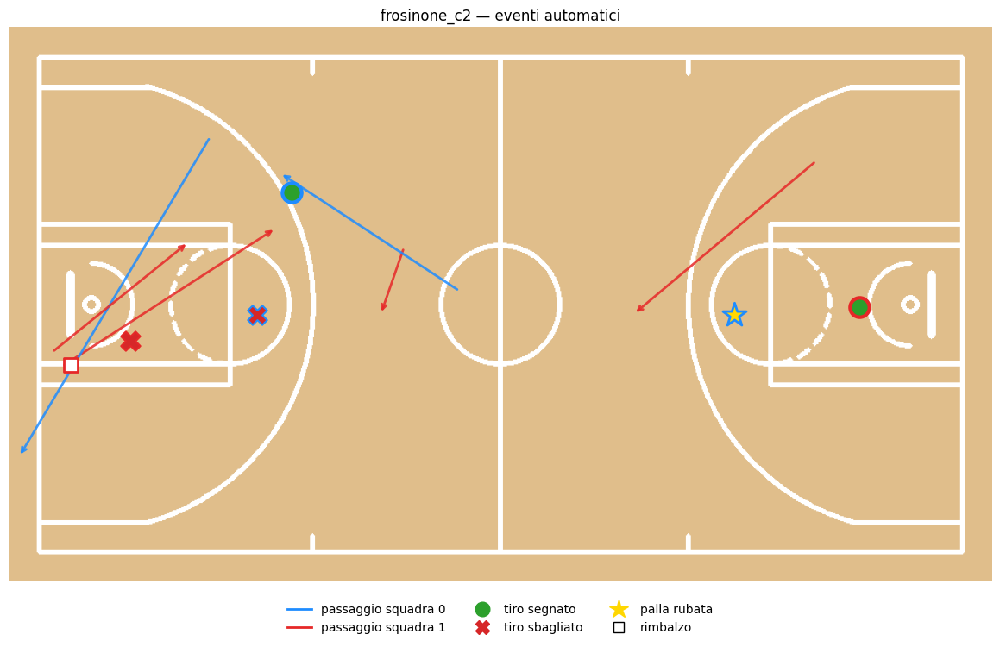

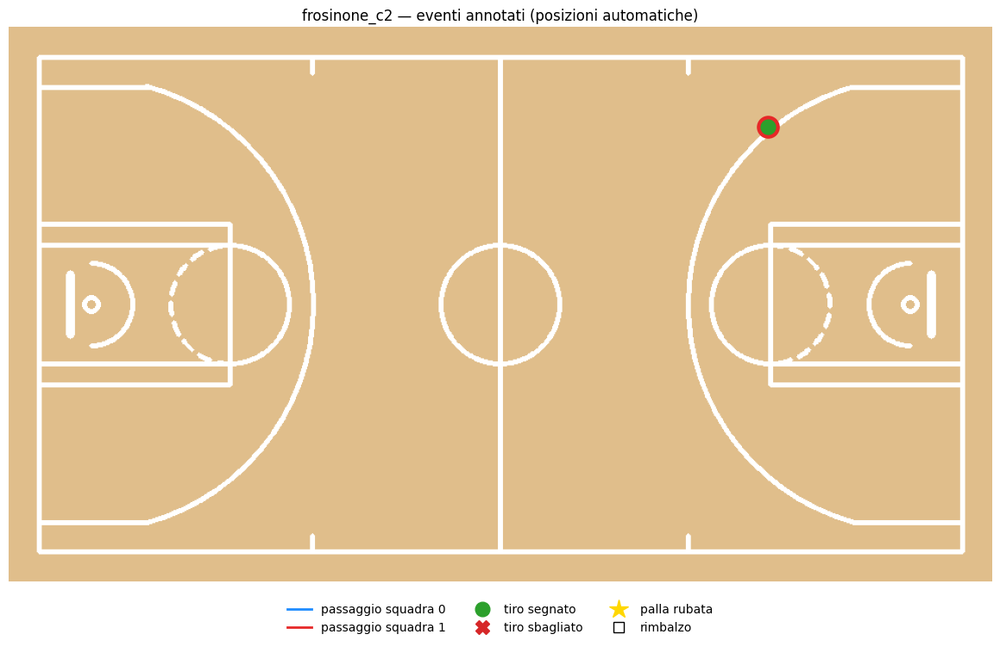

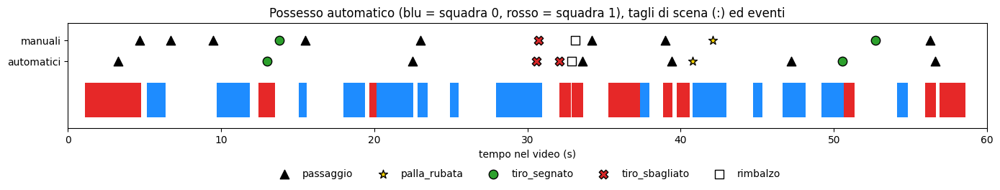

In [39]:
SCALE, PAD = 10, 30
base = draw_court(config=court, scale=SCALE, padding=PAD)
def to_map(x, y): return int(x * SCALE) + PAD, int(y * SCALE) + PAD
TEAM_RGB = {0: '#1e8cff', 1: '#e62828', -1: '#999999'}
from matplotlib.lines import Line2D

def lavagna(ev, title, path):
    fig, ax = plt.subplots(figsize=(13, 7.5)); ax.imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB))
    for r in ev.itertuples():
        if np.isnan(r.x_ft) and r.tipo != 'palla_rubata': continue
        c = TEAM_RGB.get(int(r.team), '#999')
        if r.tipo == 'passaggio' and not np.isnan(r.x2_ft):
            ax.annotate('', xy=to_map(r.x2_ft, r.y2_ft), xytext=to_map(r.x_ft, r.y_ft), arrowprops=dict(arrowstyle='->', color=c, lw=2, alpha=.85))
        elif r.tipo == 'palla_rubata':
            xx, yy = (r.x2_ft, r.y2_ft) if not np.isnan(r.x2_ft) else (r.x_ft, r.y_ft)
            if not np.isnan(xx): ax.scatter(*to_map(xx, yy), marker='*', s=420, color='gold', edgecolor=c, linewidth=2, zorder=5)
        elif r.tipo == 'tiro_segnato': ax.scatter(*to_map(r.x_ft, r.y_ft), s=260, color='#2ca02c', edgecolor=c, linewidth=3, zorder=6)
        elif r.tipo == 'tiro_sbagliato': ax.scatter(*to_map(r.x_ft, r.y_ft), s=260, marker='X', color='#d62728', edgecolor=c, linewidth=1.5, zorder=6)
        elif r.tipo == 'rimbalzo': ax.scatter(*to_map(r.x_ft, r.y_ft), s=120, marker='s', color='white', edgecolor=c, linewidth=2, zorder=4)
    leg = [Line2D([], [], color=TEAM_RGB[0], lw=2, label='passaggio squadra 0'), Line2D([], [], color=TEAM_RGB[1], lw=2, label='passaggio squadra 1'),
           Line2D([], [], marker='o', ls='', color='#2ca02c', ms=12, label='tiro segnato'), Line2D([], [], marker='X', ls='', color='#d62728', ms=12, label='tiro sbagliato'),
           Line2D([], [], marker='*', ls='', color='gold', ms=16, label='palla rubata'), Line2D([], [], marker='s', ls='', mfc='white', mec='k', ms=9, label='rimbalzo')]
    ax.legend(handles=leg, loc='upper center', bbox_to_anchor=(.5, -.02), ncol=3, frameon=False)
    ax.set_title(title); ax.axis('off'); fig.tight_layout(); fig.savefig(path, dpi=170); plt.show()

lavagna(ev_auto, f'{CLIP_ID} — eventi automatici', OUT / 'lavagna_automatica.png')
if len(ev_man): lavagna(ev_man, f'{CLIP_ID} — eventi annotati (posizioni automatiche)', OUT / 'lavagna_manuale.png')

fig, ax = plt.subplots(figsize=(14, 3))
for r in segs.itertuples():
    ax.barh(0, (r.end - r.start + 1) / FPS, left=r.start / FPS + START_S, color=TEAM_RGB.get(int(r.team), '#999'), height=.5)
for c in cuts: ax.axvline(c / FPS + START_S, color='k', ls=':', lw=1)
for a, b in ESCLUDI: ax.axvspan(a, b, color='#ccc', alpha=.6)
mk = {'passaggio': ('^', 'k'), 'palla_rubata': ('*', 'gold'), 'tiro_segnato': ('o', '#2ca02c'), 'tiro_sbagliato': ('X', '#d62728'), 'rimbalzo': ('s', 'w')}
for y0, ev, lab in [(.55, ev_auto, 'auto'), (.85, ev_man, 'manuale')]:
    for t, (m, c) in mk.items():
        e = ev[ev.tipo == t] if len(ev) else ev
        if len(e): ax.scatter(e.tempo_s, np.full(len(e), y0), marker=m, color=c, edgecolor='k', s=80, zorder=5, label=t if lab == 'auto' else None)
ax.set_yticks([.55, .85]); ax.set_yticklabels(['automatici', 'manuali']); ax.set_ylim(-.4, 1.1)
ax.set_xlabel('tempo nel video (s)'); ax.set_xlim(START_S, START_S + N / FPS)
ax.set_title('Possesso automatico (blu = squadra 0, rosso = squadra 1), tagli di scena (:) ed eventi')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.3), frameon=False); fig.tight_layout(); fig.savefig(OUT / 'linea_del_tempo.png', dpi=160); plt.show()

## 9. Video diagnostico: ID, squadre, palla (grigio = candidati, giallo = accettata), possesso, eventi e lavagna

In [40]:
EV_VIDEO = ev_man if (VIDEO_EVENTS == 'manuale' and len(ev_man)) else ev_auto
BAR = 130                                                     # striscia delle statistiche sotto la lavagna
mh = H_IMG; mw = int(base.shape[1] * mh / (base.shape[0] + BAR)); out_w = W_IMG + mw; out_w += out_w % 2
vw = cv2.VideoWriter(str(OUT / 'diagnostica_raw.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), FPS, (out_w, H_IMG))
trk_by = dict(tuple(tracks.groupby('frame')))
LABEL = {'passaggio': 'PASSAGGIO', 'palla_rubata': 'PALLA RUBATA', 'tiro_segnato': 'TIRO SEGNATO', 'tiro_sbagliato': 'TIRO SBAGLIATO', 'rimbalzo': 'RIMBALZO'}
TEAM_NAME = {0: 'BLU', 1: 'ROSSI', -1: '?'}
ev_col = lambda team: TEAM_COLORS.get(int(team), (200, 200, 200))
cut_set = set(cuts)

def stats_bar(fi, width):
    # intestazioni su due righe e centrate in colonne uguali, così non si sovrappongono
    bar = np.full((BAR, width, 3), 245, np.uint8); e = EV_VIDEO[EV_VIDEO.frame <= fi]
    cols = [('TIRI', 'segn./tent.'), ('DA 3', 'segn./tent.'), ('RIMBALZI', ''), ('PALLE', 'RUBATE')] + ([('PASSAGGI', '')] if SHOW_PASSES else [])
    x0 = 110; cw = (width - x0) // len(cols); F_ = cv2.FONT_HERSHEY_SIMPLEX
    def center(txt, j, y, sc, col, th):
        (tw, _), _ = cv2.getTextSize(txt, F_, sc, th); cv2.putText(bar, txt, (x0 + j * cw + (cw - tw) // 2, y), F_, sc, col, th)
    for j, (h1, h2) in enumerate(cols):
        center(h1, j, 26, .6, (60, 60, 60), 2)
        if h2: center(h2, j, 48, *((.6, (60, 60, 60), 2) if h2.isupper() else (.45, (110, 110, 110), 1)))   # 'RUBATE' come titolo, 'segn./tent.' come nota
    for k, team in enumerate([0, 1]):
        y = 84 + 32 * k; et = e[e.team == team]
        cv2.putText(bar, TEAM_NAME[team], (12, y), F_, .75, ev_col(team), 2)
        tiri = et.tipo.str.startswith('tiro').sum(); segn = (et.tipo == 'tiro_segnato').sum()
        t3 = et.tipo.str.startswith('tiro') & et.dettaglio.astype(str).str.contains('da 3')
        vals = [f'{segn}/{tiri}', f'{(t3 & (et.tipo == "tiro_segnato")).sum()}/{t3.sum()}', str((et.tipo == 'rimbalzo').sum()), str((et.tipo == 'palla_rubata').sum())] + ([str((et.tipo == 'passaggio').sum())] if SHOW_PASSES else [])
        for jj, v in enumerate(vals): center(v, jj, y, .85, ev_col(team), 2)
    return bar

for fi, f in frames_iter(desc='video'):
    img = f.copy(); mp = base.copy()
    if excluded[fi]:
        cv2.putText(img, 'ESCLUSO', (20, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
    past = EV_VIDEO[EV_VIDEO.frame <= fi]
    # tiri, rimbalzi e palle rubate restano per tutta la clip, nel colore della squadra
    for r in past[past.tipo.isin(['tiro_segnato', 'tiro_sbagliato', 'rimbalzo', 'palla_rubata'])].itertuples():
        xx, yy = (r.x2_ft, r.y2_ft) if (r.tipo == 'palla_rubata' and not np.isnan(r.x2_ft)) else (r.x_ft, r.y_ft)
        if np.isnan(xx): continue
        p = to_map(xx, yy); c = ev_col(r.team)
        if r.tipo == 'tiro_segnato': cv2.circle(mp, p, 12, c, 4)
        elif r.tipo == 'tiro_sbagliato': cv2.drawMarker(mp, p, c, cv2.MARKER_TILTED_CROSS, 24, 4)
        elif r.tipo == 'rimbalzo': cv2.rectangle(mp, (p[0] - 9, p[1] - 9), (p[0] + 9, p[1] + 9), c, 3)
        else: cv2.drawMarker(mp, p, c, cv2.MARKER_STAR, 26, 3)
    # passaggi: freccia che sparisce dopo PASS_SHOW_S
    if SHOW_PASSES:
        for r in past[(past.frame > fi - PASS_SHOW_S * FPS) & (past.tipo == 'passaggio')].itertuples():
            if np.isnan(r.x_ft) or np.isnan(r.x2_ft): continue
            cv2.arrowedLine(mp, to_map(r.x_ft, r.y_ft), to_map(r.x2_ft, r.y2_ft), ev_col(r.team), 3, tipLength=.08)
    holder = poss[fi]
    for r in trk_by.get(fi, pd.DataFrame()).itertuples():
        c = TEAM_COLORS.get(int(r.team), (160, 160, 160)); th = 4 if r.track_id == holder else 2
        cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, th)
        cv2.putText(img, str(r.track_id), (int(r.x1), max(14, int(r.y1) - 4)), cv2.FONT_HERSHEY_SIMPLEX, .55, c, 2)
        if not np.isnan(r.xs_ft):
            p = to_map(r.xs_ft, r.ys_ft); cv2.circle(mp, p, 9, c, -1); cv2.circle(mp, p, 9, (0, 0, 0), 1)
            if r.track_id == holder: cv2.circle(mp, p, 14, (0, 200, 255), 3)
    for cx, cy, cf in cand_by.get(fi, []):
        cv2.circle(img, (int(cx), int(cy)), 6, (150, 150, 150), 1)
    if not np.isnan(ball.bx[fi]):
        cv2.circle(img, (int(ball.bx[fi]), int(ball.by[fi])), 9, (0, 220, 255), 3)
    recent = past[past.frame > fi - 1.5 * FPS]
    if not SHOW_PASSES: recent = recent[recent.tipo != 'passaggio']
    for k, r in enumerate(recent.itertuples()):              # scritta dell'evento nel colore della squadra
        txt = LABEL.get(r.tipo, r.tipo) + ' ' + TEAM_NAME.get(int(r.team), '') + (f'  {r.dettaglio}' if r.tipo.startswith('tiro') and isinstance(r.dettaglio, str) else '')
        cv2.putText(img, txt, (12, 34 + 30 * k), cv2.FONT_HERSHEY_SIMPLEX, .8, (0, 0, 0), 6)
        cv2.putText(img, txt, (12, 34 + 30 * k), cv2.FONT_HERSHEY_SIMPLEX, .8, ev_col(r.team), 2)
    t = f'{fi / FPS + START_S:6.1f} s'
    cv2.putText(img, t, (W_IMG - 170, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 6)
    cv2.putText(img, t, (W_IMG - 170, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    if fi in cut_set: cv2.rectangle(img, (0, 0), (W_IMG - 1, H_IMG - 1), (0, 0, 255), 12)
    if Hs[fi] is None: cv2.putText(mp, 'campo non visibile', (10, 22), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 0, 255), 2)
    panel = np.vstack([mp, stats_bar(fi, mp.shape[1])])
    canvas = np.zeros((H_IMG, out_w, 3), np.uint8); canvas[:, :W_IMG] = img; canvas[:, W_IMG:W_IMG + mw] = cv2.resize(panel, (mw, mh))
    vw.write(canvas)
vw.release()
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(OUT / 'diagnostica_raw.mp4'), '-c:v', 'libx264', '-crf', '24',
                '-pix_fmt', 'yuv420p', str(OUT / 'diagnostica.mp4')], check=True)
(OUT / 'diagnostica_raw.mp4').unlink()
print('Video:', OUT / 'diagnostica.mp4')

video:   0%|          | 0/1800 [00:00<?, ?it/s]

Video: /content/drive/MyDrive/Tesi_Basket/events_amatoriali/frosinone_c2_olympic/diagnostica.mp4


## 10. Valutazione degli eventi automatici contro quelli annotati

In [41]:
def match(pred_t, ref_t, tol):
    pairs = sorted((abs(p - r), i, j) for i, p in enumerate(pred_t) for j, r in enumerate(ref_t) if abs(p - r) <= tol)
    up, ur = set(), set()
    for _, i, j in pairs:
        if i not in up and j not in ur: up.add(i); ur.add(j)
    return len(up)
if len(man):
    groups = {t: [t] for t in ['passaggio', 'palla_rubata', 'tiro_segnato', 'tiro_sbagliato', 'rimbalzo']}
    groups['tiro (tentativo)'] = ['tiro_segnato', 'tiro_sbagliato']
    rows = []
    for name, types in groups.items():
        p = ev_auto[ev_auto.tipo.isin(types)].tempo_s.values; r = man[man.tipo.isin(types)].tempo_s.values
        tp = match(p, r, EVENT_TOL_S)
        rows.append({'tipo': name, 'rilevati': len(p), 'veri': len(r), 'corretti': tp,
                     'precisione': tp / len(p) if len(p) else np.nan, 'richiamo': tp / len(r) if len(r) else np.nan})
    val = pd.DataFrame(rows).round(2); val.insert(0, 'clip', CLIP_ID)
    val.to_csv(OUT / 'valutazione_eventi.csv', index=False); display(val)
else:
    print('Nessun evento annotato per questa clip: compila', MANUAL.name, 'e riesegui le sezioni 7-10.')

summary = {'clip': CLIP_ID, 'secondi': round(N / FPS, 1), 'tagli_scena': len(cuts),
           'palla_candidati_%': round(100 * len(cand_by) / max(1, (~excluded).sum()), 1),
           'palla_accettata_%': round(100 * np.isfinite(acc[:, 0]).sum() / max(1, (~excluded).sum()), 1),
           'tracce': int(tracks.track_id.nunique()), 'segmenti_possesso': len(segs),
           'eventi_automatici': ev_auto.tipo.value_counts().to_dict(), 'eventi_manuali': len(ev_man)}
(OUT / 'riepilogo.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False)); print(json.dumps(summary, indent=2, ensure_ascii=False))

,clip,tipo,rilevati,veri,corretti,precisione,richiamo
0,frosinone_c2,passaggio,6,8,4,0.67,0.50
1,frosinone_c2,palla_rubata,1,1,0,0.00,0.00
2,frosinone_c2,tiro_segnato,2,2,1,0.50,0.50
3,frosinone_c2,tiro_sbagliato,2,1,1,0.50,1.00
4,frosinone_c2,rimbalzo,1,1,1,1.00,1.00
5,frosinone_c2,tiro (tentativo),4,3,2,0.50,0.67


{
  "clip": "frosinone_c2",
  "secondi": 60.0,
  "tagli_scena": 0,
  "palla_candidati_%": 48.7,
  "palla_accettata_%": 28.0,
  "tracce": 72,
  "segmenti_possesso": 29,
  "eventi_automatici": {
    "passaggio": 6,
    "tiro_segnato": 2,
    "tiro_sbagliato": 2,
    "rimbalzo": 1,
    "palla_rubata": 1
  },
  "eventi_manuali": 13
}


## E. Misure sull'intera partita (per la tesi)

Una clip da 60 s non rappresenta la partita. Qui si prende **un fotogramma ogni 20 s** di entrambi i tempi e, per ognuno, si misura:

- se è un'**inquadratura di gioco** (almeno 6 giocatori visti dal detector);
- quanto si muove la telecamera tra due frame consecutivi (**panoramica** se oltre 2 px: immagine mossa);
- se i keypoint del campo danno un'**omografia** (soglia 0,3, come in C);
- se il detector della palla di E4 trova **una palla** (confidenza ≥ 0,25; rilevamenti non verificati a mano).

Non servono le sezioni C–D né annotazioni: bastano il setup e la cella A. Durata: circa 10–15 minuti. Risultati in `events_amatoriali/frosinone_partita/`.

/usr/local/lib/python3.13/dist-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(


Output()

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


misure sulla partita:   0%|          | 0/270 [00:00<?, ?it/s]

,tutte le inquadrature di gioco,camera ferma,in panoramica
fotogrammi,190.0,156.0,34.0
in panoramica %,17.9,0.0,100.0
omografia %,60.0,59.0,64.7
palla trovata %,14.2,14.1,14.7


,camera ferma %,omografia %,palla trovata %
tempo_partita,,,
1T,81.3,65.9,16.5
2T,82.8,54.5,12.1


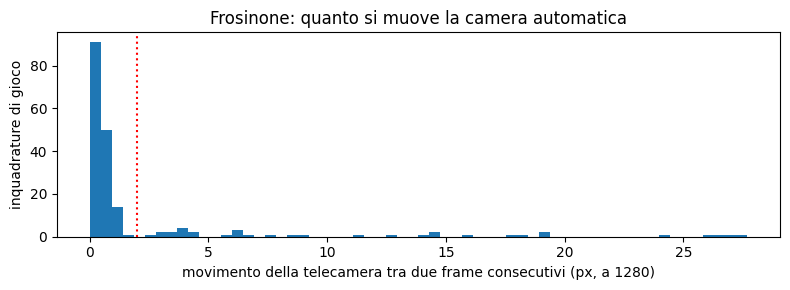

{
  "video": "frosinone_pomezia.mp4",
  "risoluzione": "1280x720",
  "campioni": 270,
  "passo_s": 20,
  "inquadrature_di_gioco": 190,
  "soglia_panoramica_px": 2.0,
  "in_panoramica_%": 17.9,
  "mov_px_mediana": 0.49,
  "omografia_%": 60.0,
  "omografia_camera_ferma_%": 59.0,
  "omografia_in_panoramica_%": 64.7,
  "palla_trovata_%": 14.2,
  "palla_trovata_camera_ferma_%": 14.1,
  "palla_trovata_in_panoramica_%": 14.7,
  "nota": "palla: rilevamenti del detector di E4 con confidenza >= 0,25, non verificati a mano"
}


In [21]:
from ultralytics import YOLO
from inference import get_model
from sports import MeasurementUnit
from sports.basketball import CourtConfiguration, League

PRIMO_TEMPO = ('0:12:10', '0:52:35')      # inizio e fine del primo tempo nel video
SECONDO_TEMPO = ('1:02:50', '1:52:00')    # inizio e fine del secondo tempo
PASSO_S, MAX_MOTION_PX, KP_CONF_E, W_E = 20, 2.0, 0.3, 1280
RES_E = ROOT / 'events_amatoriali' / 'frosinone_partita'; RES_E.mkdir(parents=True, exist_ok=True)

try:
    API_KEY
except NameError:
    try:
        from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
    except Exception: API_KEY = None
    API_KEY = API_KEY or os.environ.get('ROBOFLOW_API_KEY') or __import__('getpass').getpass('API key Roboflow: ')
det_e = YOLO(str(ROOT / 'models' / 'yolo11m_ft.pt')); ball_e = YOLO(str(ROOT / 'models' / 'ball_detector.pt'))
PL_E = [i for i, n in det_e.names.items() if n.startswith('player')] or None
court_e = get_model(model_id='basketball-court-detection-2/14', api_key=API_KEY)
V_E = np.asarray(CourtConfiguration(league=League.FIBA, measurement_unit=MeasurementUnit.FEET).vertices, dtype=np.float32)

r = subprocess.run(['ffprobe', '-v', 'error', '-select_streams', 'v:0', '-show_entries', 'stream=width,height',
                    '-of', 'csv=p=0', str(SRC)], capture_output=True, text=True)
W0, H0 = map(int, r.stdout.strip().split(',')[:2]); H_E = int(round(H0 * W_E / W0 / 2)) * 2
def grab2(t):                                   # due frame consecutivi a 1280 px, letti con ffmpeg
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.3f}', '-i', str(SRC), '-frames:v', '2',
                        '-vf', f'scale={W_E}:{H_E}', '-f', 'rawvideo', '-pix_fmt', 'bgr24', '-'], capture_output=True)
    n = W_E * H_E * 3
    if len(r.stdout) < 2 * n: return None, None
    return (np.frombuffer(r.stdout[:n], np.uint8).reshape(H_E, W_E, 3).copy(),
            np.frombuffer(r.stdout[n:2 * n], np.uint8).reshape(H_E, W_E, 3))
HANN_E = cv2.createHanningWindow((W_E // 4, H_E // 4), cv2.CV_32F)
def motion(a, b):                               # spostamento globale tra i due frame (phase correlation), in px a 1280
    g = [cv2.cvtColor(cv2.resize(x, (W_E // 4, H_E // 4), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY).astype(np.float32) for x in (a, b)]
    (dx, dy), _ = cv2.phaseCorrelate(g[0], g[1], HANN_E); return 4 * float(np.hypot(dx, dy))

T2_START = to_s(SECONDO_TEMPO[0])
ts = np.concatenate([np.arange(to_s(PRIMO_TEMPO[0]), to_s(PRIMO_TEMPO[1]), PASSO_S),
                     np.arange(to_s(SECONDO_TEMPO[0]), to_s(SECONDO_TEMPO[1]), PASSO_S)])
rows = []
for t in tqdm(ts, desc='misure sulla partita'):
    f, f2 = grab2(t)
    if f is None: continue
    rr = {'tempo_s': round(float(t), 1), 'tempo': mmss(t), 'tempo_partita': '1T' if t < T2_START else '2T',
          'giocatori': len(det_e.predict(f, conf=0.3, imgsz=640, classes=PL_E, verbose=False)[0].boxes),
          'mov_px': round(motion(f, f2), 2),
          'palla': len(ball_e.predict(f, conf=0.25, imgsz=1280, verbose=False)[0].boxes) > 0}
    omo = False; k = court_e.infer(f, confidence=0.3)[0]
    if k.predictions:
        pr = max(k.predictions, key=lambda p: p.confidence)
        pts = [p for p in pr.keypoints if p.confidence >= KP_CONF_E and 0 <= p.class_id < len(V_E)]
        if len(pts) >= 6:
            Hh, m = cv2.findHomography(V_E[[p.class_id for p in pts]], np.float32([[p.x, p.y] for p in pts]), cv2.RANSAC, 8.0)
            omo = Hh is not None and m is not None and int(m.sum()) >= 6
    rr['omografia'] = bool(omo); rows.append(rr)

M = pd.DataFrame(rows); M['di_gioco'] = M.giocatori >= 6; M['ferma'] = M.mov_px <= MAX_MOTION_PX
M.to_csv(RES_E / 'misure_partita.csv', index=False)
G = M[M.di_gioco]
pct = lambda s: round(100 * float(s.mean()), 1) if len(s) else None
tab = pd.DataFrame({
    'tutte le inquadrature di gioco': [len(G), pct(~G.ferma), pct(G.omografia), pct(G.palla)],
    'camera ferma': [int(G.ferma.sum()), 0.0, pct(G[G.ferma].omografia), pct(G[G.ferma].palla)],
    'in panoramica': [int((~G.ferma).sum()), 100.0, pct(G[~G.ferma].omografia), pct(G[~G.ferma].palla)]},
    index=['fotogrammi', 'in panoramica %', 'omografia %', 'palla trovata %'])
display(tab); tab.to_csv(RES_E / 'misure_partita_riassunto.csv')
display((G.groupby('tempo_partita')[['ferma', 'omografia', 'palla']].mean() * 100).round(1).rename(columns={'ferma': 'camera ferma %', 'omografia': 'omografia %', 'palla': 'palla trovata %'}))

plt.figure(figsize=(8, 3)); plt.hist(G.mov_px.clip(upper=60), bins=60); plt.axvline(MAX_MOTION_PX, color='r', ls=':')
plt.xlabel('movimento della telecamera tra due frame consecutivi (px, a 1280)'); plt.ylabel('inquadrature di gioco')
plt.title('Frosinone: quanto si muove la camera automatica'); plt.tight_layout(); plt.savefig(RES_E / 'movimento_camera.png', dpi=160); plt.show()

summary = {'video': SRC.name, 'risoluzione': f'{W0}x{H0}', 'campioni': len(M), 'passo_s': PASSO_S,
           'inquadrature_di_gioco': int(len(G)), 'soglia_panoramica_px': MAX_MOTION_PX,
           'in_panoramica_%': pct(~G.ferma), 'mov_px_mediana': round(float(G.mov_px.median()), 2) if len(G) else None,
           'omografia_%': pct(G.omografia), 'omografia_camera_ferma_%': pct(G[G.ferma].omografia), 'omografia_in_panoramica_%': pct(G[~G.ferma].omografia),
           'palla_trovata_%': pct(G.palla), 'palla_trovata_camera_ferma_%': pct(G[G.ferma].palla), 'palla_trovata_in_panoramica_%': pct(G[~G.ferma].palla),
           'nota': 'palla: rilevamenti del detector di E4 con confidenza >= 0,25, non verificati a mano'}
(RES_E / 'riepilogo_partita.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

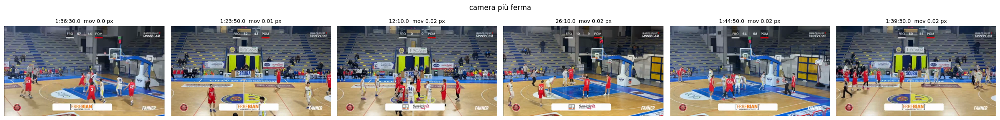

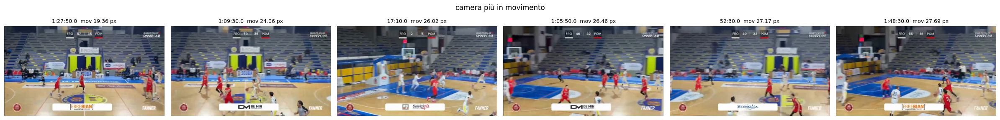

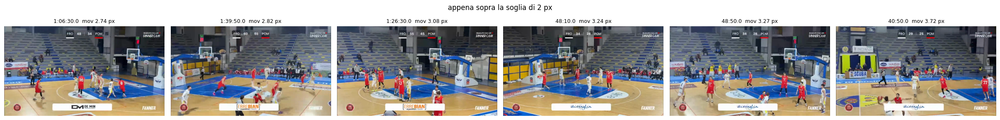

In [22]:
# E2. Verifica visiva della misura di panoramica: 6 fotogrammi con la camera più ferma e 6 con la camera più in movimento
def grab1(t, w=480):
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.3f}', '-i', str(SRC), '-frames:v', '1',
                        '-vf', f'scale={w}:-2', '-f', 'image2pipe', '-vcodec', 'png', '-'], capture_output=True)
    return cv2.imdecode(np.frombuffer(r.stdout, np.uint8), cv2.IMREAD_COLOR)
Gs = G.sort_values('mov_px')
for titolo, sel in [('camera più ferma', Gs.head(6)), ('camera più in movimento', Gs.tail(6)),
                    ('appena sopra la soglia di 2 px', Gs[Gs.mov_px > MAX_MOTION_PX].head(6))]:
    fig, ax = plt.subplots(1, len(sel), figsize=(4 * len(sel), 3))
    for a, r in zip(np.atleast_1d(ax), sel.itertuples()):
        a.imshow(cv2.cvtColor(grab1(r.tempo_s), cv2.COLOR_BGR2RGB)); a.set_title(f'{r.tempo}  mov {r.mov_px} px', fontsize=9); a.axis('off')
    plt.suptitle(titolo); plt.tight_layout(); plt.show()

## P, Q. Palla FIBA: scelta del modello sul primo tempo, misura sul secondo

**P**: E4 e due modelli pubblici di Roboflow Universe su 60 fotogrammi del primo tempo, escludendo le zone della grafica e la classe «ball-in-basket». **Q1**: estrazione di 80 fotogrammi del secondo tempo da annotare con la sola classe `ball` (solo la palla in gioco). **Q2**: precisione e recall di E4 e del modello scelto (Olympic-SK) sulla ground truth.

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


modello:   0%|          | 0/60 [00:00<?, ?it/s]

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


modello:   0%|          | 0/60 [00:00<?, ?it/s]

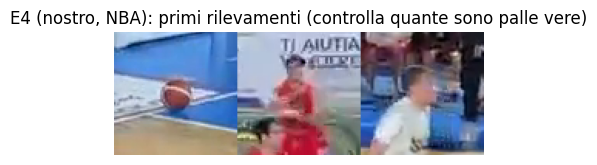

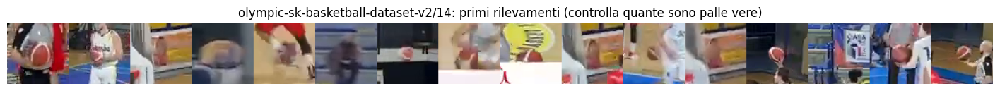

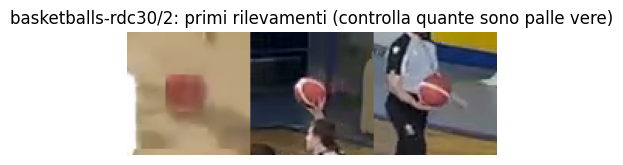

,modello,palla_trovata_%,conf_mediana,diametro_px_mediano
0,"E4 (nostro, NBA)",5.0,0.50,21.5
1,olympic-sk-basketball-dataset-v2/14,38.3,0.41,33.5
2,basketballs-rdc30/2,5.0,0.59,27.5


In [24]:
# P. Prova di modelli della palla pre-addestrati (Roboflow Universe) sul PRIMO tempo: solo per scegliere
from inference import get_model
from ultralytics import YOLO
CANDIDATI = ['olympic-sk-basketball-dataset-v2/14', 'basketballs-rdc30/2']
PRIMO_TEMPO = ('0:12:10', '0:52:35'); N_DEV = 60; CONF_P = 0.25
CLASSI_PALLA = {'ball', 'basketball'}                       # solo la palla (non 'ball-in-basket')
ZONE_GRAFICA = [(0.00, 0.80, 0.16, 1.00),                    # stemma in basso a sinistra
                (0.30, 0.86, 0.69, 0.95),                    # banner pubblicitario in basso (come SCOREBOARD_REL)
                (0.80, 0.85, 1.00, 1.00),                    # scritta FANNER in basso a destra
                (0.38, 0.05, 0.60, 0.12)]                    # punteggio in alto
try: API_KEY
except NameError:
    from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
def grabP(t, w=1280):
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.2f}', '-i', str(SRC), '-frames:v', '1', '-vf', f'scale={w}:-2',
                        '-f', 'image2pipe', '-vcodec', 'png', '-'], capture_output=True)
    return cv2.imdecode(np.frombuffer(r.stdout, np.uint8), cv2.IMREAD_COLOR) if r.stdout else None
def in_grafica(x, y, w, h): return any(a * w <= x <= c * w and b * h <= y <= d * h for a, b, c, d in ZONE_GRAFICA)
if 'frames' not in globals() or len(frames) == 0:
    ts = np.linspace(to_s(PRIMO_TEMPO[0]), to_s(PRIMO_TEMPO[1]), N_DEV)
    frames = [(t, grabP(t)) for t in tqdm(ts, desc='fotogrammi primo tempo')]
    frames = [(t, f) for t, f in frames if f is not None]

def best(cands, f):                                          # cands: lista di (x1, y1, x2, y2, conf); tolte le zone della grafica
    h, w = f.shape[:2]; c = [b for b in cands if not in_grafica((b[0] + b[2]) / 2, (b[1] + b[3]) / 2, w, h)]
    return max(c, key=lambda b: b[4]) if c else None
def run_rf(model):
    out = []
    for t, f in tqdm(frames, desc='modello'):
        p = [(q.x - q.width / 2, q.y - q.height / 2, q.x + q.width / 2, q.y + q.height / 2, q.confidence)
             for q in model.infer(f, confidence=CONF_P)[0].predictions if q.class_name.lower() in CLASSI_PALLA]
        out.append(best(p, f))
    return out
def run_e4():
    m = YOLO(str(ROOT / 'models' / 'ball_detector.pt')); out = []
    for t, f in frames:
        r = m.predict(f, conf=CONF_P, imgsz=1280, verbose=False)[0]
        out.append(best([(*b, float(c)) for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())], f))
    return out
risultati = {'E4 (nostro, NBA)': run_e4()}
for mid in CANDIDATI: risultati[mid] = run_rf(get_model(model_id=mid, api_key=API_KEY))

righe = []
for nome, res in risultati.items():
    found = [r for r in res if r is not None]
    righe.append({'modello': nome, 'palla_trovata_%': round(100 * len(found) / len(res), 1),
                  'conf_mediana': round(float(np.median([r[4] for r in found])), 2) if found else None,
                  'diametro_px_mediano': round(float(np.median([(r[2] - r[0] + r[3] - r[1]) / 2 for r in found])), 1) if found else None})
    crops = []
    for (t, f), r in zip(frames, res):
        if r is None or len(crops) >= 16: continue
        cx, cy = int((r[0] + r[2]) / 2), int((r[1] + r[3]) / 2)
        c = f[max(0, cy - 40):cy + 40, max(0, cx - 40):cx + 40]
        if c.size: crops.append(cv2.resize(c, (80, 80)))
    if crops:
        plt.figure(figsize=(18, 1.6)); plt.imshow(cv2.cvtColor(np.hstack(crops), cv2.COLOR_BGR2RGB)); plt.axis('off')
        plt.title(f'{nome}: primi rilevamenti (controlla quante sono palle vere)'); plt.show()
P_DEV = pd.DataFrame(righe); display(P_DEV)
(ROOT / 'events_amatoriali' / 'frosinone_partita').mkdir(parents=True, exist_ok=True)
P_DEV.to_csv(ROOT / 'events_amatoriali' / 'frosinone_partita' / 'prova_modelli_palla_primo_tempo.csv', index=False)

In [25]:
# Q1. Ground truth della palla sul SECONDO tempo (80 fotogrammi, da annotare solo con la classe 'ball')
import zipfile
SECONDO_TEMPO = ('1:02:50', '1:52:00'); N_Q = 80
def grabP(t, w=1280):
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.2f}', '-i', str(SRC), '-frames:v', '1', '-vf', f'scale={w}:-2',
                        '-f', 'image2pipe', '-vcodec', 'png', '-'], capture_output=True)
    return cv2.imdecode(np.frombuffer(r.stdout, np.uint8), cv2.IMREAD_COLOR) if r.stdout else None
QDIR = ROOT / 'datasets' / 'frosinone_palla_gt'; (QDIR / 'images').mkdir(parents=True, exist_ok=True)
if not any((QDIR / 'images').glob('*.jpg')):
    for t in tqdm(np.linspace(to_s(SECONDO_TEMPO[0]), to_s(SECONDO_TEMPO[1]), N_Q + 2)[1:-1], desc='estrazione'):
        f = grabP(t)
        if f is not None: cv2.imwrite(str(QDIR / 'images' / f'fro_palla_t{int(round(t * 1000)):08d}.jpg'), f, [cv2.IMWRITE_JPEG_QUALITY, 95])
else: print('Fotogrammi già estratti: non li rigenero.')
zq = ROOT / 'datasets' / 'frosinone_palla_gt_da_annotare.zip'
with zipfile.ZipFile(zq, 'w') as z:
    for p in sorted((QDIR / 'images').glob('*.jpg')): z.write(p, f'images/{p.name}')
print(f"{len(list((QDIR / 'images').glob('*.jpg')))} fotogrammi | zip da caricare su Roboflow: {zq}")

Fotogrammi già estratti: non li rigenero.
80 fotogrammi | zip da caricare su Roboflow: /content/drive/MyDrive/Tesi_Basket/datasets/frosinone_palla_gt_da_annotare.zip


In [26]:
# Q2. Valutazione della palla sul secondo tempo: E4 contro il modello scelto sul primo tempo (cella autonoma)
import zipfile, shutil
from pathlib import Path
from ultralytics import YOLO
from inference import get_model
SCELTO = 'olympic-sk-basketball-dataset-v2/14'               # scelto sul primo tempo (cella P): non cambiarlo dopo aver visto Q2
CONF_P = 0.25
CLASSI_PALLA = {'ball', 'basketball'}                       # solo la palla (non 'ball-in-basket')
ZONE_GRAFICA = [(0.00, 0.80, 0.16, 1.00), (0.30, 0.86, 0.69, 0.95), (0.80, 0.85, 1.00, 1.00), (0.38, 0.05, 0.60, 0.12)]
try: API_KEY
except NameError:
    from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
def in_grafica(x, y, w, h): return any(a * w <= x <= c * w and b * h <= y <= d * h for a, b, c, d in ZONE_GRAFICA)
def best(cands, f):
    h, w = f.shape[:2]; c = [b for b in cands if not in_grafica((b[0] + b[2]) / 2, (b[1] + b[3]) / 2, w, h)]
    return max(c, key=lambda b: b[4]) if c else None

QDIR = ROOT / 'datasets' / 'frosinone_palla_gt'
QZIP = ROOT / 'datasets' / 'frosinone_palla_gt_annotato.zip'
assert QZIP.is_file(), f'Manca {QZIP}: esporta da Roboflow'
tmpq = Path('/content/fro_palla_rf'); shutil.rmtree(tmpq, ignore_errors=True); zipfile.ZipFile(QZIP).extractall(tmpq)
GTQ = {}
for lp in tmpq.rglob('*.txt'):
    if lp.parent.name != 'labels': continue
    stem = lp.stem.split('_jpg')[0]; img = QDIR / 'images' / f'{stem}.jpg'
    if not img.is_file(): continue
    GTQ[stem] = np.loadtxt(lp, ndmin=2)[:, :5] if lp.stat().st_size else np.zeros((0, 5))
n_tot = len(list((QDIR / 'images').glob('*.jpg')))
print(f'fotogrammi annotati: {len(GTQ)} su {n_tot} ({n_tot - len(GTQ)} cancellati) | con la palla visibile: {sum(len(a) > 0 for a in GTQ.values())}')

e4 = YOLO(str(ROOT / 'models' / 'ball_detector.pt')); rf = get_model(model_id=SCELTO, api_key=API_KEY)
def det_e4(f):
    r = e4.predict(f, conf=CONF_P, imgsz=1280, verbose=False)[0]
    return best([(*b, float(c)) for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())], f)
def det_rf(f):
    p = [(q.x - q.width / 2, q.y - q.height / 2, q.x + q.width / 2, q.y + q.height / 2, q.confidence)
         for q in rf.infer(f, confidence=CONF_P)[0].predictions if q.class_name.lower() in CLASSI_PALLA]
    return best(p, f)
rowsq = []
for stem, a in tqdm(GTQ.items(), desc='valutazione'):
    f = cv2.imread(str(QDIR / 'images' / f'{stem}.jpg')); h, w = f.shape[:2]
    g = [((x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h) for _, x, y, bw, bh in a]
    for nome, fn in [('E4 (nostro, NBA)', det_e4), (SCELTO, det_rf)]:
        d = fn(f); ok = False
        if d is not None and g:
            cx, cy = (d[0] + d[2]) / 2, (d[1] + d[3]) / 2
            ok = any(x1 - 5 <= cx <= x2 + 5 and y1 - 5 <= cy <= y2 + 5 for x1, y1, x2, y2 in g)   # centro dentro la palla vera (±5 px)
        rowsq.append({'frame': stem, 'modello': nome, 'palla_vera': len(g) > 0, 'rilevata': d is not None, 'giusta': ok,
                      'diametro_vero_px': float(np.mean([(x2 - x1 + y2 - y1) / 2 for x1, y1, x2, y2 in g])) if g else np.nan})
Q = pd.DataFrame(rowsq)
RQ = Q.groupby('modello', sort=False).apply(lambda q: pd.Series({
    'rilevamenti': int(q.rilevata.sum()), 'giusti': int(q.giusta.sum()), 'palle_vere': int(q.palla_vera.sum()),
    'precisione': round(q.giusta.sum() / max(1, q.rilevata.sum()), 3),
    'recall': round(q.giusta.sum() / max(1, q.palla_vera.sum()), 3)}))
display(RQ)
print(f"diametro della palla annotata: mediana {Q.diametro_vero_px.median():.1f} px "
      f"(min {Q.diametro_vero_px.min():.1f}, max {Q.diametro_vero_px.max():.1f})")
out_q = ROOT / 'events_amatoriali' / 'frosinone_partita'; out_q.mkdir(parents=True, exist_ok=True)
RQ.to_csv(out_q / 'palla_secondo_tempo_E4_vs_scelto.csv'); Q.to_csv(out_q / 'palla_secondo_tempo_dettaglio.csv', index=False)

fotogrammi annotati: 77 su 80 (3 cancellati) | con la palla visibile: 38


Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


valutazione:   0%|          | 0/77 [00:00<?, ?it/s]

/tmp/ipykernel_2730/3597104259.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  RQ = Q.groupby('modello', sort=False).apply(lambda q: pd.Series({


,rilevamenti,giusti,palle_vere,precisione,recall
modello,,,,,
"E4 (nostro, NBA)",6.0,4.0,38.0,0.667,0.105
olympic-sk-basketball-dataset-v2/14,26.0,12.0,38.0,0.462,0.316


diametro della palla annotata: mediana 22.8 px (min 16.0, max 34.5)


## R. Confronto E4 / Olympic-SK: video affiancato e tabella

Si esegue **dopo** aver completato la pipeline con `BALL_SOURCE = 'olympic'` (cella C → D0 → detection → … → riepilogo). Usa i risultati con la palla E4 in `events_amatoriali/frosinone_c2/` e quelli con Olympic-SK in `events_amatoriali/frosinone_c2_olympic/`.

In [42]:
# R. Confronto E4 / Olympic-SK sulla stessa clip: video affiancato e tabella dei riepiloghi
CLIP_BASE = 'frosinone_c2'
DIR_E4, DIR_OL = ROOT / 'events_amatoriali' / CLIP_BASE, ROOT / 'events_amatoriali' / f'{CLIP_BASE}_olympic'
VA, VB = DIR_E4 / 'diagnostica.mp4', DIR_OL / 'diagnostica.mp4'
assert VA.is_file() and VB.is_file(), f'Mancano i video: {VA.is_file()=} {VB.is_file()=}'

# tabella: riepiloghi delle due esecuzioni
ra, rb = json.loads((DIR_E4 / 'riepilogo.json').read_text()), json.loads((DIR_OL / 'riepilogo.json').read_text())
keys = ['palla_candidati_%', 'palla_accettata_%', 'segmenti_possesso', 'tracce']
CMP = pd.DataFrame({'palla E4 (NBA)': [ra.get(k) for k in keys] + [json.dumps(ra.get('eventi_automatici'))],
                    'palla Olympic-SK (FIBA)': [rb.get(k) for k in keys] + [json.dumps(rb.get('eventi_automatici'))]},
                   index=keys + ['eventi_automatici'])
display(CMP); CMP.to_csv(DIR_OL / 'confronto_E4_olympic.csv')

# video affiancato (sinistra E4, destra Olympic-SK)
ca, cb = cv2.VideoCapture(str(VA)), cv2.VideoCapture(str(VB))
fps = ca.get(cv2.CAP_PROP_FPS) or 30
n = int(min(ca.get(cv2.CAP_PROP_FRAME_COUNT), cb.get(cv2.CAP_PROP_FRAME_COUNT)))
TW = 960                                                     # larghezza di ciascuna metà
tmp_v = DIR_OL / 'confronto_tmp.mp4'; out_v = DIR_OL / 'confronto_E4_vs_olympic.mp4'; vw = None
for _ in tqdm(range(n), desc='video di confronto'):
    oa, fa = ca.read(); ob, fb = cb.read()
    if not (oa and ob): break
    halves = []
    for f, lab, col in [(fa, 'palla E4 (NBA)', (0, 0, 255)), (fb, 'palla Olympic-SK (FIBA)', (0, 200, 0))]:
        f = cv2.resize(f, (TW, int(round(f.shape[0] * TW / f.shape[1]))))
        cv2.rectangle(f, (0, 0), (TW, 34), (0, 0, 0), -1)
        cv2.putText(f, lab, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, col, 2, cv2.LINE_AA); halves.append(f)
    h = min(x.shape[0] for x in halves); frame = np.hstack([x[:h] for x in halves])
    if vw is None: vw = cv2.VideoWriter(str(tmp_v), cv2.VideoWriter_fourcc(*'mp4v'), fps, (frame.shape[1], frame.shape[0]))
    vw.write(frame)
ca.release(); cb.release(); vw.release()
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(tmp_v), '-c:v', 'libx264', '-crf', '23', '-pix_fmt', 'yuv420p', str(out_v)], check=True)
tmp_v.unlink(missing_ok=True)
print('Video di confronto:', out_v)


,palla E4 (NBA),palla Olympic-SK (FIBA)
palla_candidati_%,23.6,48.7
palla_accettata_%,15.1,28.0
segmenti_possesso,27,29
tracce,72,72
eventi_automatici,"{""tiro_segnato"": 2, ""passaggio"": 2, ""palla_rub...","{""passaggio"": 6, ""tiro_segnato"": 2, ""tiro_sbag..."


video di confronto:   0%|          | 0/1800 [00:00<?, ?it/s]

Video di confronto: /content/drive/MyDrive/Tesi_Basket/events_amatoriali/frosinone_c2_olympic/confronto_E4_vs_olympic.mp4


## R2. Confronto omografia keypoint / manuale

Dopo aver rieseguito la pipeline con le celle 4M: a sinistra i keypoint automatici, a destra l'omografia manuale propagata.

In [43]:
# R2. Confronto omografia keypoint / omografia manuale (stessa clip, stessa palla): video affiancato e tabella
DIR_E4, DIR_OL = OUT / 'omografia_keypoint', OUT          # sinistra: keypoint automatici | destra: omografia manuale
VA, VB = DIR_E4 / 'diagnostica.mp4', DIR_OL / 'diagnostica.mp4'
assert VA.is_file() and VB.is_file(), f'Mancano i video: {VA.is_file()=} {VB.is_file()=}'

# tabella: riepiloghi delle due esecuzioni
ra, rb = json.loads((DIR_E4 / 'riepilogo.json').read_text()), json.loads((DIR_OL / 'riepilogo.json').read_text())
keys = ['palla_candidati_%', 'palla_accettata_%', 'segmenti_possesso', 'tracce']
CMP = pd.DataFrame({'omografia keypoint': [ra.get(k) for k in keys] + [json.dumps(ra.get('eventi_automatici'))],
                    'omografia manuale': [rb.get(k) for k in keys] + [json.dumps(rb.get('eventi_automatici'))]},
                   index=keys + ['eventi_automatici'])
display(CMP); CMP.to_csv(DIR_OL / 'confronto_omografia.csv')

# video affiancato (sinistra E4, destra Olympic-SK)
ca, cb = cv2.VideoCapture(str(VA)), cv2.VideoCapture(str(VB))
fps = ca.get(cv2.CAP_PROP_FPS) or 30
n = int(min(ca.get(cv2.CAP_PROP_FRAME_COUNT), cb.get(cv2.CAP_PROP_FRAME_COUNT)))
TW = 960                                                     # larghezza di ciascuna metà
tmp_v = DIR_OL / 'confronto_omo_tmp.mp4'; out_v = DIR_OL / 'confronto_omografia_keypoint_vs_manuale.mp4'; vw = None
for _ in tqdm(range(n), desc='video di confronto'):
    oa, fa = ca.read(); ob, fb = cb.read()
    if not (oa and ob): break
    halves = []
    for f, lab, col in [(fa, 'omografia keypoint', (0, 0, 255)), (fb, 'omografia manuale', (0, 200, 0))]:
        f = cv2.resize(f, (TW, int(round(f.shape[0] * TW / f.shape[1]))))
        cv2.rectangle(f, (0, 0), (TW, 34), (0, 0, 0), -1)
        cv2.putText(f, lab, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, col, 2, cv2.LINE_AA); halves.append(f)
    h = min(x.shape[0] for x in halves); frame = np.hstack([x[:h] for x in halves])
    if vw is None: vw = cv2.VideoWriter(str(tmp_v), cv2.VideoWriter_fourcc(*'mp4v'), fps, (frame.shape[1], frame.shape[0]))
    vw.write(frame)
ca.release(); cb.release(); vw.release()
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(tmp_v), '-c:v', 'libx264', '-crf', '23', '-pix_fmt', 'yuv420p', str(out_v)], check=True)
tmp_v.unlink(missing_ok=True)
print('Video di confronto:', out_v)

,omografia keypoint,omografia manuale
palla_candidati_%,48.7,48.7
palla_accettata_%,28.0,28.0
segmenti_possesso,29,29
tracce,72,72
eventi_automatici,"{""passaggio"": 6, ""tiro_segnato"": 2, ""tiro_sbag...","{""passaggio"": 6, ""tiro_segnato"": 2, ""tiro_sbag..."


video di confronto:   0%|          | 0/1800 [00:00<?, ?it/s]

Video di confronto: /content/drive/MyDrive/Tesi_Basket/events_amatoriali/frosinone_c2_olympic/confronto_omografia_keypoint_vs_manuale.mp4
